In [1]:
!pip -q install xgboost shap streamlit joblib

import os
import re
import gc
import glob
import json
import shutil
import zipfile
import warnings
import py_compile
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
import shap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)


PREDICTION_DAY = 56
VLE_START_DAY = 0

RANDOM_STATE = 42
CV_FOLDS = 5

RF_ITERATIONS = 15
XGB_ITERATIONS = 15

MIN_SUBGROUP_N = 30

CUTOFFS_TO_COMPARE = [
    28,
    42,
    56,
    70
]

# I change this to False if the files are already in /content.
UPLOAD_FILES = True

DATA_DIR = "/content"

OUTPUT_DIR = "/content/project_outputs_FINAL"
TABLE_DIR = f"{OUTPUT_DIR}/tables"
FIG_DIR = f"{OUTPUT_DIR}/figures"
MODEL_DIR = f"{OUTPUT_DIR}/models"
TEST_DIR = f"{OUTPUT_DIR}/testing"


if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)


for folder in [
    OUTPUT_DIR,
    TABLE_DIR,
    FIG_DIR,
    MODEL_DIR,
    TEST_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )


print("Prediction day:", PREDICTION_DAY)
print("Cross-validation folds:", CV_FOLDS)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 61.5 MB/s eta 0:00:00
Prediction day: 56
Cross-validation folds: 5


In [2]:
# I upload the OULAD files when needed.

if UPLOAD_FILES:

    from google.colab import files

    uploaded = files.upload()

    print("\nUploaded files:")

    for name in uploaded:
        print(name)

    del uploaded
    gc.collect()


def find_csv(prefix):

    patterns = [
        f"{DATA_DIR}/{prefix}.csv",
        f"{DATA_DIR}/{prefix}(*).csv",
        f"{DATA_DIR}/{prefix}*.csv"
    ]

    matches = []

    for pattern in patterns:
        matches.extend(
            glob.glob(pattern)
        )

    matches = list(
        dict.fromkeys(matches)
    )

    matches = [
        path
        for path in matches
        if "project_outputs" not in path
        and "modelling_dataset" not in path
    ]

    if len(matches) == 0:

        raise FileNotFoundError(
            f"{prefix}.csv was not found in {DATA_DIR}"
        )

    return sorted(
        matches,
        key=os.path.getmtime,
        reverse=True
    )[0]


FILES = {
    "courses":
        find_csv("courses"),

    "assessments":
        find_csv("assessments"),

    "studentInfo":
        find_csv("studentInfo"),

    "studentRegistration":
        find_csv("studentRegistration"),

    "studentAssessment":
        find_csv("studentAssessment"),

    "studentVle":
        find_csv("studentVle"),

    "vle":
        find_csv("vle")
}


print("\nFiles selected:")

for name, path in FILES.items():

    print(
        f"{name:22s}: "
        f"{os.path.basename(path)}"
    )

Saving assessments.csv to assessments.csv
Saving courses.csv to courses.csv
Saving OULAD.names to OULAD.names
Saving studentAssessment.csv to studentAssessment.csv
Saving studentInfo.csv to studentInfo.csv
Saving studentRegistration.csv to studentRegistration.csv
Saving studentVle.csv to studentVle.csv
Saving vle.csv to vle.csv

Uploaded files:
assessments.csv
courses.csv
OULAD.names
studentAssessment.csv
studentInfo.csv
studentRegistration.csv
studentVle.csv
vle.csv

Files selected:
courses               : courses.csv
assessments           : assessments.csv
studentInfo           : studentInfo.csv
studentRegistration   : studentRegistration.csv
studentAssessment     : studentAssessment.csv
studentVle            : studentVle.csv
vle                   : vle.csv


In [3]:
# I load the smaller tables first.

NA_VALUES = [
    "?",
    "",
    "NA",
    "N/A",
    "NULL",
    "null"
]


courses = pd.read_csv(
    FILES["courses"],
    na_values=NA_VALUES
)

assessments = pd.read_csv(
    FILES["assessments"],
    na_values=NA_VALUES
)

student_info_original = pd.read_csv(
    FILES["studentInfo"],
    na_values=NA_VALUES
)

student_registration = pd.read_csv(
    FILES["studentRegistration"],
    na_values=NA_VALUES
)

student_assessment = pd.read_csv(
    FILES["studentAssessment"],
    na_values=NA_VALUES
)

vle = pd.read_csv(
    FILES["vle"],
    na_values=NA_VALUES
)


for col in ["date", "weight"]:

    assessments[col] = pd.to_numeric(
        assessments[col],
        errors="coerce"
    )


for col in [
    "date_submitted",
    "is_banked",
    "score"
]:

    student_assessment[col] = pd.to_numeric(
        student_assessment[col],
        errors="coerce"
    )


for col in [
    "date_registration",
    "date_unregistration"
]:

    student_registration[col] = pd.to_numeric(
        student_registration[col],
        errors="coerce"
    )


for df in [
    courses,
    assessments,
    student_info_original,
    student_registration,
    vle
]:

    if "code_module" in df.columns:
        df["code_module"] = df["code_module"].astype(str)

    if "code_presentation" in df.columns:
        df["code_presentation"] = df["code_presentation"].astype(str)


for df in [
    student_info_original,
    student_registration
]:

    df["id_student"] = pd.to_numeric(
        df["id_student"],
        errors="raise"
    ).astype("int64")


KEYS = [
    "code_module",
    "code_presentation",
    "id_student"
]


audit_tables = {
    "courses":
        courses,

    "assessments":
        assessments,

    "studentInfo":
        student_info_original,

    "studentRegistration":
        student_registration,

    "studentAssessment":
        student_assessment,

    "vle":
        vle
}


audit_rows = []


for name, df in audit_tables.items():

    audit_rows.append({
        "table":
            name,

        "rows":
            len(df),

        "columns":
            df.shape[1],

        "duplicate_rows":
            int(
                df.duplicated().sum()
            ),

        "missing_values":
            int(
                df.isna().sum().sum()
            )
    })


audit_df = pd.DataFrame(
    audit_rows
)


print(
    audit_df.to_string(
        index=False
    )
)


audit_df.to_csv(
    f"{TABLE_DIR}/dataset_audit.csv",
    index=False
)

              table   rows  columns  duplicate_rows  missing_values
            courses     22        3               0               0
        assessments    206        6               0              11
        studentInfo  32593       12               0            1111
studentRegistration  32593        5               0           22566
  studentAssessment 173912        5               0             173
                vle   6364        6               0           10486


In [4]:
# I only keep students who are still enrolled after Day 56.

eligible_registration = student_registration[
    student_registration[
        "date_unregistration"
    ].isna()
    |
    (
        student_registration[
            "date_unregistration"
        ] > PREDICTION_DAY
    )
].copy()


eligible_registration = (
    eligible_registration
    .drop_duplicates(
        subset=KEYS
    )
)


eligible_keys = (
    eligible_registration[
        KEYS
    ]
    .drop_duplicates()
)


student_info = (
    student_info_original
    .merge(
        eligible_keys,
        on=KEYS,
        how="inner"
    )
)


original_n = len(
    student_info_original
)

eligible_n = len(
    student_info
)

excluded_n = (
    original_n
    -
    eligible_n
)


cohort_flow = pd.DataFrame([
    {
        "stage":
            "Original student-module records",

        "n":
            original_n
    },
    {
        "stage":
            "Withdrawn on/before Day 56",

        "n":
            excluded_n
    },
    {
        "stage":
            "Eligible Day-56 cohort",

        "n":
            eligible_n
    }
])


print(
    cohort_flow.to_string(
        index=False
    )
)


cohort_flow.to_csv(
    f"{TABLE_DIR}/cohort_flow.csv",
    index=False
)


valid_results = {
    "Fail",
    "Withdrawn",
    "Pass",
    "Distinction"
}


unexpected = (
    set(
        student_info[
            "final_result"
        ]
        .dropna()
        .unique()
    )
    -
    valid_results
)


if unexpected:

    raise ValueError(
        f"Unexpected outcomes: {unexpected}"
    )


# I create the binary academic-risk target here.

student_info[
    "at_risk"
] = (
    student_info[
        "final_result"
    ]
    .isin([
        "Fail",
        "Withdrawn"
    ])
    .astype(int)
)


target_distribution = (
    student_info[
        "at_risk"
    ]
    .value_counts()
    .rename_axis(
        "at_risk"
    )
    .reset_index(
        name="count"
    )
)


target_distribution[
    "label"
] = target_distribution[
    "at_risk"
].map({
    0:
        "Not At Risk",

    1:
        "At Risk"
})


target_distribution[
    "percentage"
] = (
    target_distribution[
        "count"
    ]
    /
    target_distribution[
        "count"
    ].sum()
    *
    100
)


print(
    target_distribution
)


target_distribution.to_csv(
    f"{TABLE_DIR}/target_distribution.csv",
    index=False
)

                          stage     n
Original student-module records 32593
     Withdrawn on/before Day 56  6071
         Eligible Day-56 cohort 26522
   at_risk  count        label  percentage
0        0  15385  Not At Risk   58.008446
1        1  11137      At Risk   41.991554


In [5]:
# I compare several early prediction points.

non_exam = assessments[
    (
        assessments[
            "assessment_type"
        ] != "Exam"
    )
    &
    assessments[
        "date"
    ].notna()
].copy()


assessment_cutoff_rows = []


for cutoff in CUTOFFS_TO_COMPARE:

    temp = non_exam[
        non_exam[
            "date"
        ] <= cutoff
    ]


    eligible_temp = student_registration[
        student_registration[
            "date_unregistration"
        ].isna()
        |
        (
            student_registration[
                "date_unregistration"
            ] > cutoff
        )
    ]


    assessment_cutoff_rows.append({
        "prediction_day":
            cutoff,

        "assessments_available":
            len(temp),

        "module_presentations":
            temp[
                [
                    "code_module",
                    "code_presentation"
                ]
            ]
            .drop_duplicates()
            .shape[0],

        "assessment_weight":
            float(
                temp[
                    "weight"
                ]
                .fillna(0)
                .sum()
            ),

        "eligible_records":
            eligible_temp[
                KEYS
            ]
            .drop_duplicates()
            .shape[0]
    })


assessment_cutoff_df = pd.DataFrame(
    assessment_cutoff_rows
)


# I read the large VLE file in chunks.

MAX_CUTOFF = max(
    CUTOFFS_TO_COMPARE
)

CHUNK_SIZE = 750_000

vle_parts = []

raw_vle_rows = 0


for chunk_number, chunk in enumerate(

    pd.read_csv(
        FILES["studentVle"],
        chunksize=CHUNK_SIZE
    ),

    start=1
):

    chunk[
        "code_module"
    ] = chunk[
        "code_module"
    ].astype(str)


    chunk[
        "code_presentation"
    ] = chunk[
        "code_presentation"
    ].astype(str)


    chunk[
        "id_student"
    ] = pd.to_numeric(
        chunk[
            "id_student"
        ],
        errors="raise"
    ).astype(
        "int64"
    )


    raw_vle_rows += len(
        chunk
    )


    early = chunk[
        (
            chunk[
                "date"
            ] >= VLE_START_DAY
        )
        &
        (
            chunk[
                "date"
            ] <= MAX_CUTOFF
        )
    ].copy()


    if len(early) > 0:

        vle_parts.append(
            early
        )


    print(
        f"Chunk {chunk_number}: "
        f"{len(chunk):,} read, "
        f"{len(early):,} retained"
    )


early_vle = pd.concat(
    vle_parts,
    ignore_index=True
)


del vle_parts
gc.collect()


registration_dates = (
    student_registration[
        KEYS
        +
        [
            "date_unregistration"
        ]
    ]
    .drop_duplicates(
        subset=KEYS
    )
)


early_vle = early_vle.merge(
    registration_dates,
    on=KEYS,
    how="left"
)


vle_cutoff_rows = []


for cutoff in CUTOFFS_TO_COMPARE:

    temp = early_vle[
        (
            early_vle[
                "date"
            ] <= cutoff
        )
        &
        (
            early_vle[
                "date_unregistration"
            ].isna()
            |
            (
                early_vle[
                    "date_unregistration"
                ] > cutoff
            )
        )
    ]


    vle_cutoff_rows.append({
        "prediction_day":
            cutoff,

        "vle_records":
            len(temp),

        "students_with_activity":
            temp[
                KEYS
            ]
            .drop_duplicates()
            .shape[0],

        "total_clicks":
            int(
                temp[
                    "sum_click"
                ].sum()
            )
    })


vle_cutoff_df = pd.DataFrame(
    vle_cutoff_rows
)


prediction_cutoff_comparison = (
    assessment_cutoff_df
    .merge(
        vle_cutoff_df,
        on="prediction_day",
        how="left"
    )
)


print(
    prediction_cutoff_comparison
    .to_string(
        index=False
    )
)


prediction_cutoff_comparison.to_csv(
    f"{TABLE_DIR}/prediction_cutoff_comparison.csv",
    index=False
)

Chunk 1: 750,000 read, 307,089 retained
Chunk 2: 750,000 read, 291,062 retained
Chunk 3: 750,000 read, 374,498 retained
Chunk 4: 750,000 read, 279,139 retained
Chunk 5: 750,000 read, 254,232 retained
Chunk 6: 750,000 read, 349,220 retained
Chunk 7: 750,000 read, 262,032 retained
Chunk 8: 750,000 read, 364,024 retained
Chunk 9: 750,000 read, 398,111 retained
Chunk 10: 750,000 read, 224,718 retained
Chunk 11: 750,000 read, 247,151 retained
Chunk 12: 750,000 read, 285,276 retained
Chunk 13: 750,000 read, 463,891 retained
Chunk 14: 750,000 read, 57,372 retained
Chunk 15: 155,280 read, 33,379 retained
 prediction_day  assessments_available  module_presentations  assessment_weight  eligible_records  vle_records  students_with_activity  total_clicks
             28                     17                    16              123.5             27538      2105461                   26312       7766285
             42                     24                    19              217.5             27024 

In [6]:
# I create assessment features available by Day 56.

due_assessments = assessments[
    (
        assessments[
            "assessment_type"
        ] != "Exam"
    )
    &
    assessments[
        "date"
    ].notna()
    &
    (
        assessments[
            "date"
        ] <= PREDICTION_DAY
    )
].copy()


due_assessments = (
    due_assessments
    .rename(
        columns={
            "date":
                "assessment_date",

            "weight":
                "assessment_weight"
        }
    )
)


due_by_module = (
    due_assessments
    .groupby(
        [
            "code_module",
            "code_presentation"
        ],
        as_index=False
    )
    .agg(
        assess_due_count=(
            "id_assessment",
            "nunique"
        ),

        assess_total_due_weight=(
            "assessment_weight",
            "sum"
        )
    )
)


early_assessment = (
    student_assessment
    .merge(
        due_assessments[
            [
                "id_assessment",
                "code_module",
                "code_presentation",
                "assessment_date",
                "assessment_weight"
            ]
        ],
        on="id_assessment",
        how="inner"
    )
)


early_assessment[
    "id_student"
] = pd.to_numeric(
    early_assessment[
        "id_student"
    ],
    errors="raise"
).astype(
    "int64"
)


early_assessment = early_assessment[
    early_assessment[
        "date_submitted"
    ] <= PREDICTION_DAY
].copy()


early_assessment = early_assessment.merge(
    eligible_keys,
    on=KEYS,
    how="inner"
)


early_assessment[
    "is_late"
] = (
    early_assessment[
        "date_submitted"
    ]
    >
    early_assessment[
        "assessment_date"
    ]
).astype(int)


early_assessment[
    "days_from_deadline"
] = (
    early_assessment[
        "date_submitted"
    ]
    -
    early_assessment[
        "assessment_date"
    ]
)


early_assessment[
    "weighted_score"
] = (
    early_assessment[
        "score"
    ]
    *
    early_assessment[
        "assessment_weight"
    ]
)


assessment_features = (
    early_assessment
    .groupby(
        KEYS,
        as_index=False
    )
    .agg(
        assess_submitted_count=(
            "id_assessment",
            "nunique"
        ),

        assess_mean_score=(
            "score",
            "mean"
        ),

        assess_min_score=(
            "score",
            "min"
        ),

        assess_max_score=(
            "score",
            "max"
        ),

        assess_score_std=(
            "score",
            "std"
        ),

        assess_late_count=(
            "is_late",
            "sum"
        ),

        assess_banked_count=(
            "is_banked",
            "sum"
        ),

        assess_mean_submission_day=(
            "date_submitted",
            "mean"
        ),

        assess_mean_days_from_deadline=(
            "days_from_deadline",
            "mean"
        ),

        weighted_score_sum=(
            "weighted_score",
            "sum"
        ),

        assess_submitted_weight=(
            "assessment_weight",
            "sum"
        )
    )
)


assessment_features[
    "assess_weighted_mean_score"
] = np.where(

    assessment_features[
        "assess_submitted_weight"
    ] > 0,

    assessment_features[
        "weighted_score_sum"
    ]
    /
    assessment_features[
        "assess_submitted_weight"
    ],

    assessment_features[
        "assess_mean_score"
    ]
)


assessment_features.drop(
    columns=[
        "weighted_score_sum"
    ],
    inplace=True
)


print(
    "Assessment feature records:",
    f"{len(assessment_features):,}"
)

Assessment feature records: 22,462


In [7]:
# I create VLE engagement features up to Day 56.

student_vle = early_vle[
    (
        early_vle[
            "date"
        ] <= PREDICTION_DAY
    )
    &
    (
        early_vle[
            "date_unregistration"
        ].isna()
        |
        (
            early_vle[
                "date_unregistration"
            ] > PREDICTION_DAY
        )
    )
].copy()


student_vle.drop(
    columns=[
        "date_unregistration"
    ],
    inplace=True
)


del early_vle
gc.collect()


student_vle = student_vle.merge(
    vle[
        [
            "id_site",
            "code_module",
            "code_presentation",
            "activity_type"
        ]
    ],
    on=[
        "id_site",
        "code_module",
        "code_presentation"
    ],
    how="left"
)


student_vle[
    "activity_type"
] = student_vle[
    "activity_type"
].fillna(
    "unknown"
).astype(str)


vle_general = (
    student_vle
    .groupby(
        KEYS,
        as_index=False
    )
    .agg(
        vle_total_clicks=(
            "sum_click",
            "sum"
        ),

        vle_active_days=(
            "date",
            "nunique"
        ),

        vle_unique_sites=(
            "id_site",
            "nunique"
        ),

        vle_first_activity_day=(
            "date",
            "min"
        ),

        vle_last_activity_day=(
            "date",
            "max"
        )
    )
)


vle_general[
    "vle_avg_clicks_active_day"
] = (
    vle_general[
        "vle_total_clicks"
    ]
    /
    vle_general[
        "vle_active_days"
    ].replace(
        0,
        np.nan
    )
)


student_vle[
    "clicks_first14"
] = np.where(
    student_vle[
        "date"
    ] <= 13,
    student_vle[
        "sum_click"
    ],
    0
)


student_vle[
    "clicks_days14_27"
] = np.where(
    (
        student_vle[
            "date"
        ] >= 14
    )
    &
    (
        student_vle[
            "date"
        ] <= 27
    ),
    student_vle[
        "sum_click"
    ],
    0
)


student_vle[
    "clicks_last14"
] = np.where(
    student_vle[
        "date"
    ] >= (
        PREDICTION_DAY - 13
    ),
    student_vle[
        "sum_click"
    ],
    0
)


vle_windows = (
    student_vle
    .groupby(
        KEYS,
        as_index=False
    )
    .agg(
        vle_clicks_first14=(
            "clicks_first14",
            "sum"
        ),

        vle_clicks_days14_27=(
            "clicks_days14_27",
            "sum"
        ),

        vle_clicks_last14=(
            "clicks_last14",
            "sum"
        )
    )
)


vle_windows[
    "vle_engagement_trend_ratio"
] = (
    vle_windows[
        "vle_clicks_last14"
    ] + 1
) / (
    vle_windows[
        "vle_clicks_first14"
    ] + 1
)


activity_clicks = pd.pivot_table(
    student_vle,
    index=KEYS,
    columns="activity_type",
    values="sum_click",
    aggfunc="sum",
    fill_value=0
).reset_index()


def clean_name(value):

    value = str(
        value
    ).lower()

    value = re.sub(
        r"[^a-z0-9]+",
        "_",
        value
    )

    return value.strip(
        "_"
    )


activity_clicks.columns = [
    col
    if col in KEYS
    else "vle_clicks_" + clean_name(col)

    for col in activity_clicks.columns
]


vle_features = (
    vle_general
    .merge(
        vle_windows,
        on=KEYS,
        how="outer"
    )
    .merge(
        activity_clicks,
        on=KEYS,
        how="outer"
    )
)


print(
    "VLE feature records:",
    f"{len(vle_features):,}"
)


del student_vle
del activity_clicks

gc.collect()

VLE feature records: 25,741


7

In [8]:
# I combine the student, assessment and VLE features.

model_df = student_info.copy()


registration_safe = (
    eligible_registration[
        KEYS
        +
        [
            "date_registration"
        ]
    ]
    .drop_duplicates(
        subset=KEYS
    )
)


model_df = model_df.merge(
    registration_safe,
    on=KEYS,
    how="left"
)


model_df = model_df.merge(
    courses,
    on=[
        "code_module",
        "code_presentation"
    ],
    how="left"
)


model_df = model_df.merge(
    due_by_module,
    on=[
        "code_module",
        "code_presentation"
    ],
    how="left"
)


model_df = model_df.merge(
    assessment_features,
    on=KEYS,
    how="left"
)


model_df = model_df.merge(
    vle_features,
    on=KEYS,
    how="left"
)


zero_assessment_cols = [
    "assess_due_count",
    "assess_total_due_weight",
    "assess_submitted_count",
    "assess_late_count",
    "assess_banked_count",
    "assess_submitted_weight"
]


for col in zero_assessment_cols:

    if col in model_df.columns:

        model_df[
            col
        ] = model_df[
            col
        ].fillna(
            0
        )


model_df[
    "assess_missed_count"
] = (
    model_df[
        "assess_due_count"
    ]
    -
    model_df[
        "assess_submitted_count"
    ]
).clip(
    lower=0
)


model_df[
    "assess_submission_rate"
] = np.where(

    model_df[
        "assess_due_count"
    ] > 0,

    model_df[
        "assess_submitted_count"
    ]
    /
    model_df[
        "assess_due_count"
    ],

    np.nan
)


vle_cols = [
    col
    for col in model_df.columns
    if col.startswith(
        "vle_"
    )
]


for col in vle_cols:

    model_df[
        col
    ] = model_df[
        col
    ].fillna(
        0
    )


assert (
    "date_unregistration"
    not in model_df.columns
)


assert (
    model_df[
        KEYS
    ]
    .duplicated()
    .sum()
    == 0
)


missing_summary = (
    model_df
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
    .reset_index()
)


missing_summary.columns = [
    "variable",
    "missing_count"
]


missing_summary[
    "missing_percentage"
] = (
    missing_summary[
        "missing_count"
    ]
    /
    len(
        model_df
    )
    *
    100
)


missing_summary.to_csv(
    f"{TABLE_DIR}/missingness.csv",
    index=False
)


leakage_audit = pd.DataFrame([
    {
        "information":
            "final_result",

        "decision":
            "Target creation only"
    },
    {
        "information":
            "date_unregistration",

        "decision":
            "Cohort eligibility only"
    },
    {
        "information":
            "Students withdrawn by Day 56",

        "decision":
            "Excluded"
    },
    {
        "information":
            "VLE activity after Day 56",

        "decision":
            "Excluded"
    },
    {
        "information":
            "Assessments after Day 56",

        "decision":
            "Excluded"
    }
])


leakage_audit.to_csv(
    f"{TABLE_DIR}/leakage_audit.csv",
    index=False
)


feature_rows = []


for col in model_df.columns:

    if col in [
        "id_student",
        "final_result",
        "at_risk"
    ]:

        continue


    if col.startswith(
        "assess_"
    ):

        category = (
            "Early assessment behaviour"
        )

    elif col.startswith(
        "vle_"
    ):

        category = (
            "Early VLE engagement"
        )

    elif col in [
        "code_module",
        "code_presentation",
        "module_presentation_length"
    ]:

        category = (
            "Course context"
        )

    elif col == "date_registration":

        category = (
            "Registration context"
        )

    else:

        category = (
            "Student context"
        )


    feature_rows.append({
        "feature":
            col,

        "category":
            category,

        "dtype":
            str(
                model_df[
                    col
                ].dtype
            )
    })


feature_dictionary = pd.DataFrame(
    feature_rows
)


feature_dictionary.to_csv(
    f"{TABLE_DIR}/feature_dictionary.csv",
    index=False
)


MODEL_DATA_PATH = (
    f"{OUTPUT_DIR}/"
    "oulad_modelling_dataset_day56_FINAL.csv"
)


model_df.to_csv(
    MODEL_DATA_PATH,
    index=False
)


print(
    "Final records:",
    f"{len(model_df):,}"
)

print(
    "Final columns:",
    model_df.shape[1]
)

Final records: 26,522
Final columns: 59


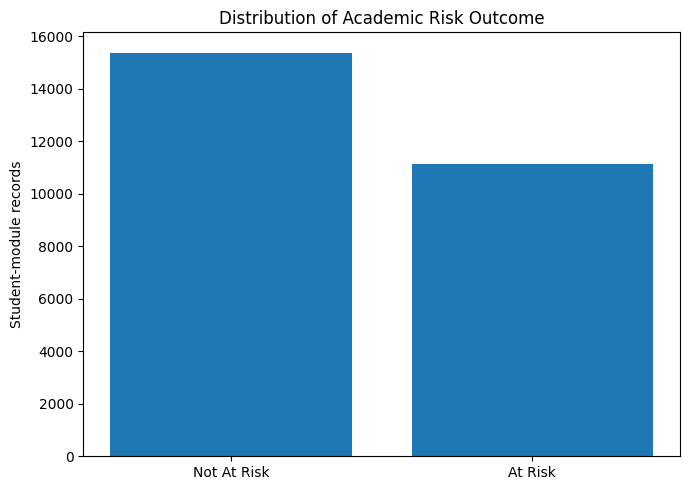

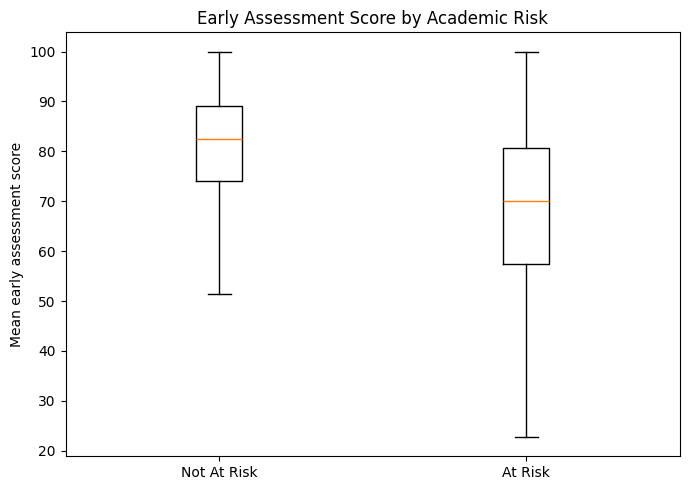

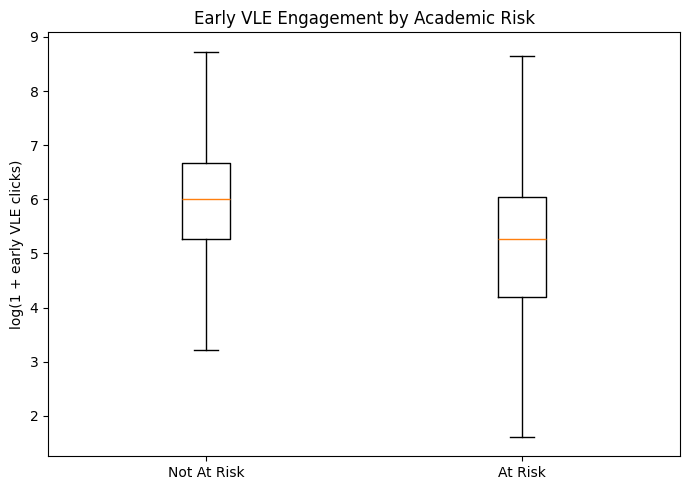

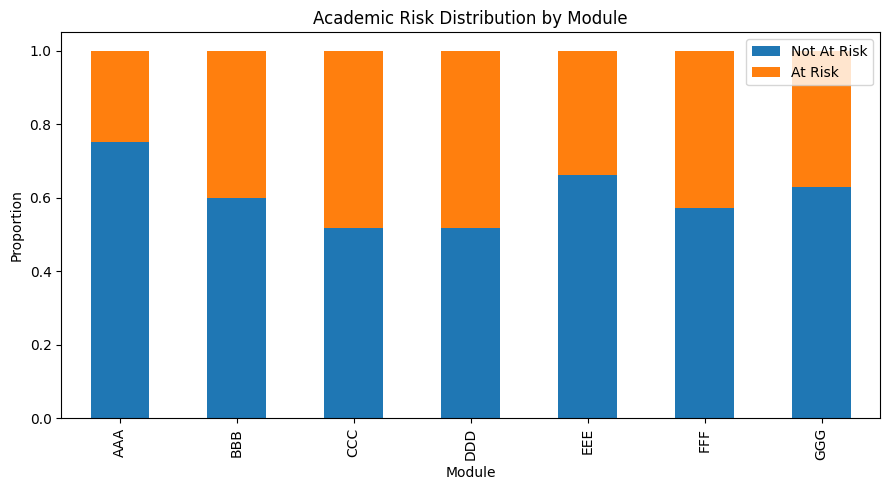

In [9]:
# I create the main descriptive figures.

target_counts = (
    model_df[
        "at_risk"
    ]
    .value_counts()
    .sort_index()
)


fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.bar(
    [
        "Not At Risk",
        "At Risk"
    ],
    target_counts.values
)

ax.set_title(
    "Distribution of Academic Risk Outcome"
)

ax.set_ylabel(
    "Student-module records"
)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


score0 = model_df.loc[
    model_df[
        "at_risk"
    ] == 0,
    "assess_mean_score"
].dropna()


score1 = model_df.loc[
    model_df[
        "at_risk"
    ] == 1,
    "assess_mean_score"
].dropna()


if len(score0) > 0 and len(score1) > 0:

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )

    ax.boxplot(
        [
            score0,
            score1
        ],
        labels=[
            "Not At Risk",
            "At Risk"
        ],
        showfliers=False
    )

    ax.set_title(
        "Early Assessment Score by Academic Risk"
    )

    ax.set_ylabel(
        "Mean early assessment score"
    )

    plt.tight_layout()

    plt.savefig(
        f"{FIG_DIR}/assessment_score_by_risk.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


click0 = np.log1p(
    model_df.loc[
        model_df[
            "at_risk"
        ] == 0,
        "vle_total_clicks"
    ]
)


click1 = np.log1p(
    model_df.loc[
        model_df[
            "at_risk"
        ] == 1,
        "vle_total_clicks"
    ]
)


fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.boxplot(
    [
        click0,
        click1
    ],
    labels=[
        "Not At Risk",
        "At Risk"
    ],
    showfliers=False
)

ax.set_title(
    "Early VLE Engagement by Academic Risk"
)

ax.set_ylabel(
    "log(1 + early VLE clicks)"
)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/vle_engagement_by_risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


module_risk = pd.crosstab(
    model_df[
        "code_module"
    ],
    model_df[
        "at_risk"
    ],
    normalize="index"
)


module_risk.columns = [
    "Not At Risk",
    "At Risk"
]


module_risk.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title(
    "Academic Risk Distribution by Module"
)

plt.xlabel(
    "Module"
)

plt.ylabel(
    "Proportion"
)

plt.tight_layout()

plt.savefig(
    f"{FIG_DIR}/risk_by_module.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [10]:
# I keep the final hold-out set separate from model and threshold selection.

DROP_FEATURES = [
    "id_student",
    "final_result",
    "at_risk"
]


feature_columns = [
    col
    for col in model_df.columns
    if col not in DROP_FEATURES
]


assert (
    "date_unregistration"
    not in feature_columns
)

assert (
    "final_result"
    not in feature_columns
)


X = model_df[
    feature_columns
].copy()


y = model_df[
    "at_risk"
].astype(
    int
).copy()


groups = model_df[
    "id_student"
].copy()


categorical_cols = [
    col
    for col in X.columns
    if (
        X[col].dtype == "object"
        or
        str(
            X[col].dtype
        ).startswith(
            "string"
        )
        or
        str(
            X[col].dtype
        ).startswith(
            "category"
        )
    )
]


numeric_cols = [
    col
    for col in X.columns
    if col not in categorical_cols
]


# Final untouched hold-out split.

outer_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


train_idx, test_idx = next(
    outer_split.split(
        X,
        y,
        groups
    )
)


X_train_full = X.iloc[
    train_idx
].copy()

X_test = X.iloc[
    test_idx
].copy()


y_train_full = y.iloc[
    train_idx
].copy()

y_test = y.iloc[
    test_idx
].copy()


groups_train_full = groups.iloc[
    train_idx
].copy()

groups_test = groups.iloc[
    test_idx
].copy()


# I reserve part of training only for threshold selection.

threshold_split = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE + 1
)


dev_idx, threshold_idx = next(
    threshold_split.split(
        X_train_full,
        y_train_full,
        groups_train_full
    )
)


X_dev = X_train_full.iloc[
    dev_idx
].copy()

X_threshold = X_train_full.iloc[
    threshold_idx
].copy()


y_dev = y_train_full.iloc[
    dev_idx
].copy()

y_threshold = y_train_full.iloc[
    threshold_idx
].copy()


groups_dev = groups_train_full.iloc[
    dev_idx
].copy()

groups_threshold = groups_train_full.iloc[
    threshold_idx
].copy()


train_test_overlap = (
    set(
        groups_train_full
    )
    .intersection(
        set(
            groups_test
        )
    )
)


dev_threshold_overlap = (
    set(
        groups_dev
    )
    .intersection(
        set(
            groups_threshold
        )
    )
)


assert (
    len(
        train_test_overlap
    ) == 0
)


assert (
    len(
        dev_threshold_overlap
    ) == 0
)


print(
    "Model-development records:",
    f"{len(X_dev):,}"
)

print(
    "Threshold-validation records:",
    f"{len(X_threshold):,}"
)

print(
    "Final hold-out records:",
    f"{len(X_test):,}"
)

print(
    "Train/test student overlap:",
    len(
        train_test_overlap
    )
)

print(
    "Development/threshold overlap:",
    len(
        dev_threshold_overlap
    )
)


numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "scaler",
        StandardScaler()
    )
])


try:

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

except TypeError:

    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )


categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "onehot",
        encoder
    )
])


preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_cols
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_cols
    )
])

Model-development records: 16,992
Threshold-validation records: 4,233
Final hold-out records: 5,297
Train/test student overlap: 0
Development/threshold overlap: 0


In [13]:
risk_rate = y_dev.mean()

minority_share = min(
    risk_rate,
    1 - risk_rate
)

USE_CLASS_WEIGHT = (
    minority_share < 0.35
)


lr_weight = (
    "balanced"
    if USE_CLASS_WEIGHT
    else None
)

rf_weight = (
    "balanced"
    if USE_CLASS_WEIGHT
    else None
)


negative_n = int(
    (y_dev == 0).sum()
)

positive_n = int(
    (y_dev == 1).sum()
)


xgb_weight = (
    negative_n / positive_n
    if USE_CLASS_WEIGHT
    else 1.0
)


lr_pipeline = Pipeline([
    (
        "preprocess",
        clone(preprocessor)
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2500,
            solver="liblinear",
            class_weight=lr_weight,
            random_state=RANDOM_STATE
        )
    )
])


rf_pipeline = Pipeline([
    (
        "preprocess",
        clone(preprocessor)
    ),
    (
        "model",
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight=rf_weight,
            n_jobs=1
        )
    )
])


xgb_pipeline = Pipeline([
    (
        "preprocess",
        clone(preprocessor)
    ),
    (
        "model",
        XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            tree_method="hist",
            scale_pos_weight=xgb_weight,
            n_jobs=1,
            verbosity=0
        )
    )
])


inner_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}


# I keep a compact Logistic Regression grid.

lr_grid = {
    "model__C": [
        0.1,
        1,
        5
    ],

    "model__penalty": [
        "l1",
        "l2"
    ]
}


# I use a focused Random Forest search.

rf_space = {
    "model__n_estimators": [
        150,
        250,
        350
    ],

    "model__max_depth": [
        None,
        12,
        20
    ],

    "model__min_samples_split": [
        2,
        5
    ],

    "model__min_samples_leaf": [
        1,
        2,
        4
    ],

    "model__max_features": [
        "sqrt",
        0.5
    ]
}


# I use a focused XGBoost search.

xgb_space = {
    "model__n_estimators": [
        150,
        250,
        350
    ],

    "model__max_depth": [
        2,
        3,
        5
    ],

    "model__learning_rate": [
        0.03,
        0.05,
        0.1
    ],

    "model__subsample": [
        0.8,
        1.0
    ],

    "model__colsample_bytree": [
        0.8,
        1.0
    ],

    "model__min_child_weight": [
        1,
        3
    ],

    "model__reg_lambda": [
        1,
        2
    ]
}


RF_ITERATIONS = 8
XGB_ITERATIONS = 8


print(
    "Development at-risk rate:",
    round(risk_rate, 4)
)

print(
    "Class weighting:",
    USE_CLASS_WEIGHT
)

print(
    "RF random combinations:",
    RF_ITERATIONS
)

print(
    "XGB random combinations:",
    XGB_ITERATIONS
)

Development at-risk rate: 0.4193
Class weighting: False
RF random combinations: 8
XGB random combinations: 8


In [14]:
# I tune the three models with the same grouped validation design.

print("Training Logistic Regression...")

lr_search = GridSearchCV(
    lr_pipeline,
    lr_grid,
    scoring=scoring,
    refit="f1",
    cv=inner_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

lr_search.fit(
    X_dev,
    y_dev,
    groups=groups_dev
)


print("\nTraining Random Forest...")

rf_search = RandomizedSearchCV(
    rf_pipeline,
    rf_space,
    n_iter=RF_ITERATIONS,
    scoring=scoring,
    refit="f1",
    cv=inner_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

rf_search.fit(
    X_dev,
    y_dev,
    groups=groups_dev
)


print("\nTraining XGBoost...")

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    xgb_space,
    n_iter=XGB_ITERATIONS,
    scoring=scoring,
    refit="f1",
    cv=inner_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

xgb_search.fit(
    X_dev,
    y_dev,
    groups=groups_dev
)


searches = {
    "Logistic Regression":
        lr_search,

    "Random Forest":
        rf_search,

    "XGBoost":
        xgb_search
}


cv_rows = []


for model_name, search in searches.items():

    i = search.best_index_

    cv_rows.append({
        "model":
            model_name,

        "cv_accuracy":
            search.cv_results_[
                "mean_test_accuracy"
            ][i],

        "cv_precision":
            search.cv_results_[
                "mean_test_precision"
            ][i],

        "cv_recall":
            search.cv_results_[
                "mean_test_recall"
            ][i],

        "cv_f1":
            search.cv_results_[
                "mean_test_f1"
            ][i],

        "cv_roc_auc":
            search.cv_results_[
                "mean_test_roc_auc"
            ][i],

        "cv_pr_auc":
            search.cv_results_[
                "mean_test_pr_auc"
            ][i],

        "cv_f1_sd":
            search.cv_results_[
                "std_test_f1"
            ][i],

        "best_parameters":
            str(
                search.best_params_
            )
    })


cv_results = pd.DataFrame(
    cv_rows
)


cv_results.to_csv(
    f"{TABLE_DIR}/model_selection_cv_results.csv",
    index=False
)


print("\nCompleted model selection.\n")

print(
    cv_results
    .round(4)
    .to_string(
        index=False
    )
)

Training Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Training Random Forest...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Training XGBoost...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Completed model selection.

              model  cv_accuracy  cv_precision  cv_recall  cv_f1  cv_roc_auc  cv_pr_auc  cv_f1_sd                                                                                                                                                                                 best_parameters
Logistic Regression       0.7657        0.7746     0.6224 0.6901      0.8309     0.8068    0.0046                                                                                                                                                       {'model__C': 0.1, 'model__penalty': 'l2'}
      Random Forest       0.7671        0.7791     0.6204 0.6906      0.8295     0.8101    0.0075                                  

In [15]:
# I select the model from CV and the threshold from separate validation data.

preferred_row = (
    cv_results
    .sort_values(
        [
            "cv_pr_auc",
            "cv_f1",
            "cv_recall"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0]
)


PREFERRED_MODEL_NAME = (
    preferred_row[
        "model"
    ]
)


preferred_dev_model = (
    searches[
        PREFERRED_MODEL_NAME
    ]
    .best_estimator_
)


print(
    "Preferred model:",
    PREFERRED_MODEL_NAME
)


print(
    "\nSelected CV results:"
)


print(
    preferred_row[
        [
            "cv_precision",
            "cv_recall",
            "cv_f1",
            "cv_roc_auc",
            "cv_pr_auc"
        ]
    ]
)


# I use the separate threshold-validation set only for threshold selection.

threshold_probability = (
    preferred_dev_model
    .predict_proba(
        X_threshold
    )[:, 1]
)


threshold_rows = []


for threshold in np.arange(
    0.10,
    0.901,
    0.005
):

    threshold = round(
        float(threshold),
        3
    )


    prediction = (
        threshold_probability
        >=
        threshold
    ).astype(int)


    threshold_rows.append({
        "threshold":
            threshold,

        "accuracy":
            accuracy_score(
                y_threshold,
                prediction
            ),

        "precision":
            precision_score(
                y_threshold,
                prediction,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_threshold,
                prediction,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_threshold,
                prediction,
                zero_division=0
            ),

        "f2":
            fbeta_score(
                y_threshold,
                prediction,
                beta=2,
                zero_division=0
            )
    })


threshold_results = pd.DataFrame(
    threshold_rows
)


best_threshold_row = (
    threshold_results
    .sort_values(
        [
            "f2",
            "recall",
            "precision"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0]
)


OPERATING_THRESHOLD = float(
    best_threshold_row[
        "threshold"
    ]
)


threshold_results.to_csv(
    f"{TABLE_DIR}/threshold_validation_results.csv",
    index=False
)


print(
    "\nSelected operating threshold:",
    OPERATING_THRESHOLD
)


print(
    "\nThreshold-validation performance:"
)


print(
    best_threshold_row
    .round(4)
)

Preferred model: XGBoost

Selected CV results:
cv_precision    0.772375
cv_recall       0.634294
cv_f1           0.696526
cv_roc_auc      0.833701
cv_pr_auc       0.814911
Name: 2, dtype: object

Selected operating threshold: 0.19

Threshold-validation performance:
threshold    0.1900
accuracy     0.6468
precision    0.5432
recall       0.9195
f1           0.6829
f2           0.8076
Name: 18, dtype: float64


In [16]:
# I refit the fixed models on all training data before final testing.

final_models = {}


for name, search in searches.items():

    final_model = clone(
        search.best_estimator_
    )


    final_model.fit(
        X_train_full,
        y_train_full
    )


    final_models[
        name
    ] = final_model


preferred_model = (
    final_models[
        PREFERRED_MODEL_NAME
    ]
)


def evaluate_holdout(
    model_name,
    model,
    threshold=0.5
):

    probability = (
        model
        .predict_proba(
            X_test
        )[:, 1]
    )


    prediction = (
        probability
        >=
        threshold
    ).astype(int)


    result = {
        "model":
            model_name,

        "threshold":
            threshold,

        "accuracy":
            accuracy_score(
                y_test,
                prediction
            ),

        "precision":
            precision_score(
                y_test,
                prediction,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_test,
                prediction,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_test,
                prediction,
                zero_division=0
            ),

        "f2":
            fbeta_score(
                y_test,
                prediction,
                beta=2,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_test,
                probability
            ),

        "pr_auc":
            average_precision_score(
                y_test,
                probability
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_test,
                prediction
            ),

        "brier_score":
            brier_score_loss(
                y_test,
                probability
            )
    }


    return (
        result,
        prediction,
        probability
    )


test_rows = []

predictions = {}

probabilities = {}


for name, model in final_models.items():

    result, pred, prob = evaluate_holdout(
        name,
        model,
        threshold=0.5
    )


    test_rows.append(
        result
    )


    predictions[
        name
    ] = pred


    probabilities[
        name
    ] = prob


test_results = pd.DataFrame(
    test_rows
)


preferred_probability = (
    probabilities[
        PREFERRED_MODEL_NAME
    ]
)


operational_prediction = (
    preferred_probability
    >=
    OPERATING_THRESHOLD
).astype(int)


operational_result = pd.DataFrame([
    {
        "model":
            PREFERRED_MODEL_NAME,

        "threshold":
            OPERATING_THRESHOLD,

        "accuracy":
            accuracy_score(
                y_test,
                operational_prediction
            ),

        "precision":
            precision_score(
                y_test,
                operational_prediction,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_test,
                operational_prediction,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_test,
                operational_prediction,
                zero_division=0
            ),

        "f2":
            fbeta_score(
                y_test,
                operational_prediction,
                beta=2,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_test,
                preferred_probability
            ),

        "pr_auc":
            average_precision_score(
                y_test,
                preferred_probability
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_test,
                operational_prediction
            ),

        "brier_score":
            brier_score_loss(
                y_test,
                preferred_probability
            )
    }
])


final_model_comparison = (
    cv_results
    .merge(
        test_results,
        on="model",
        how="left"
    )
)


test_results.to_csv(
    f"{TABLE_DIR}/holdout_test_results_default_threshold.csv",
    index=False
)


operational_result.to_csv(
    f"{TABLE_DIR}/preferred_model_operating_threshold_results.csv",
    index=False
)


final_model_comparison.to_csv(
    f"{TABLE_DIR}/final_model_comparison.csv",
    index=False
)


print(
    "\nHold-out results at threshold 0.50:\n"
)


print(
    test_results
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nPreferred model at operating threshold:\n"
)


print(
    operational_result
    .round(4)
    .to_string(
        index=False
    )
)


Hold-out results at threshold 0.50:

              model  threshold  accuracy  precision  recall     f1     f2  roc_auc  pr_auc  balanced_accuracy  brier_score
Logistic Regression        0.5    0.7544     0.7602  0.6207 0.6834 0.6443   0.8256  0.8026             0.7374       0.1654
      Random Forest        0.5    0.7584     0.7728  0.6149 0.6849 0.6411   0.8238  0.8019             0.7401       0.1658
            XGBoost        0.5    0.7627     0.7727  0.6295 0.6938 0.6538   0.8292  0.8087             0.7457       0.1637

Preferred model at operating threshold:

  model  threshold  accuracy  precision  recall     f1     f2  roc_auc  pr_auc  balanced_accuracy  brier_score
XGBoost       0.19    0.6458      0.551  0.9213 0.6896 0.8122   0.8292  0.8087             0.6809       0.1637


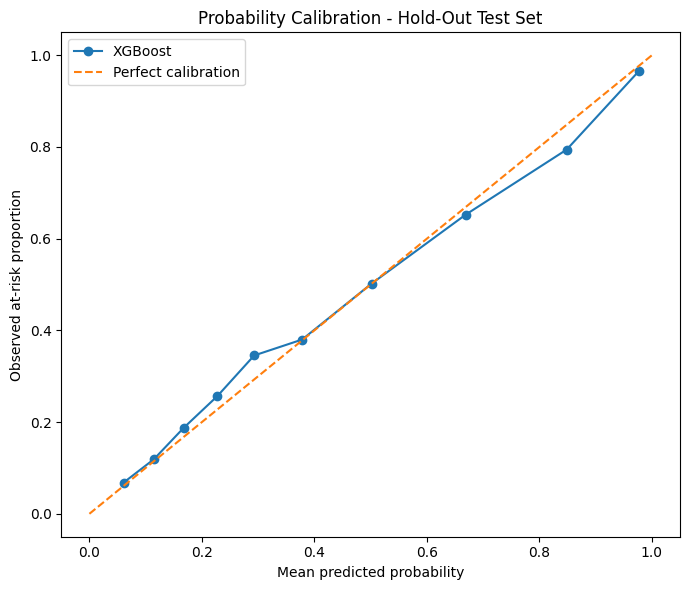

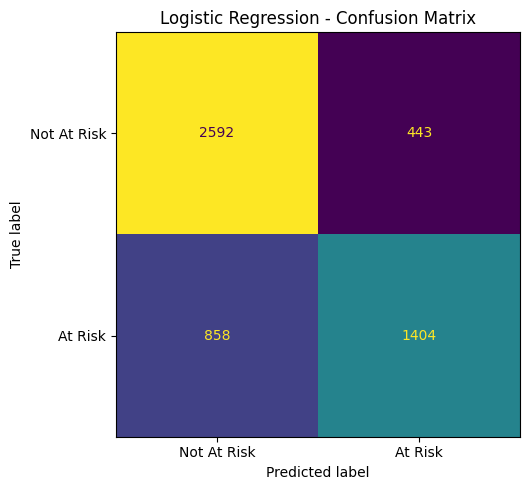

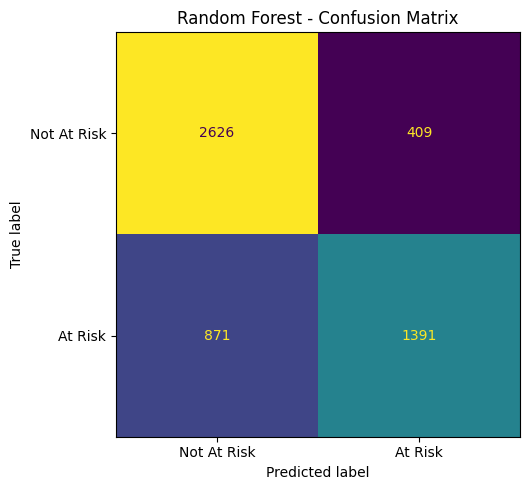

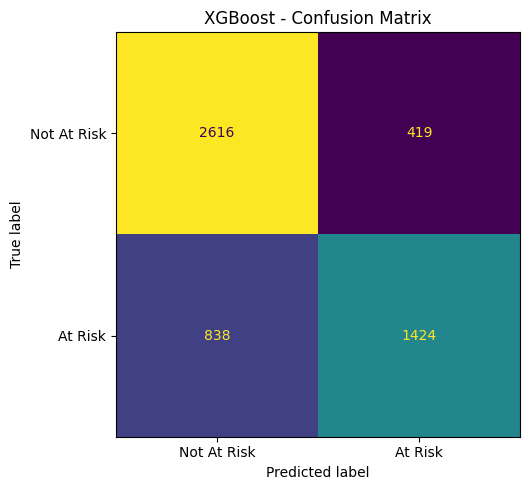

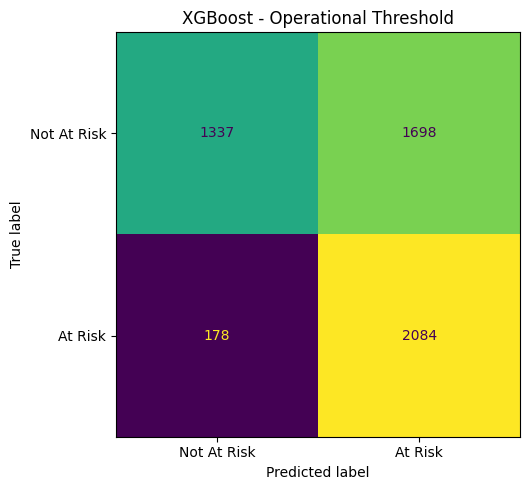

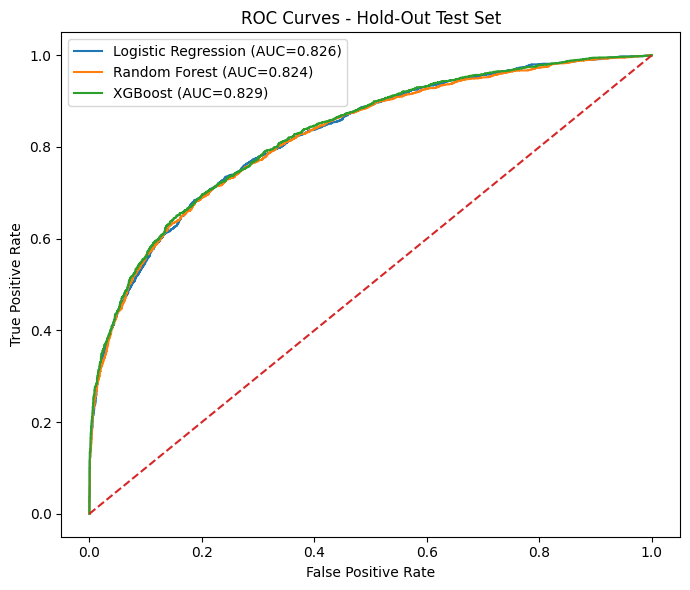

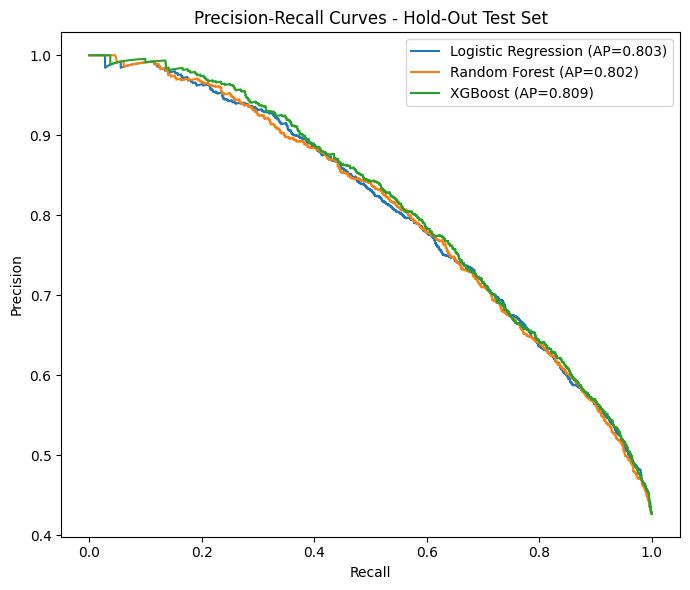

prediction_type
True Positive     2084
False Positive    1698
True Negative     1337
False Negative     178
Name: count, dtype: int64


In [17]:
# I evaluate probability calibration and classification errors.

prob_true, prob_pred = calibration_curve(
    y_test,
    preferred_probability,
    n_bins=10,
    strategy="quantile"
)


calibration_df = pd.DataFrame({
    "mean_predicted_probability":
        prob_pred,

    "observed_positive_rate":
        prob_true,

    "absolute_gap":
        np.abs(
            prob_true
            -
            prob_pred
        )
})


calibration_df.to_csv(
    f"{TABLE_DIR}/calibration_curve.csv",
    index=False
)


fig, ax = plt.subplots(
    figsize=(7, 6)
)


ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    label=PREFERRED_MODEL_NAME
)


ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)


ax.set_xlabel(
    "Mean predicted probability"
)

ax.set_ylabel(
    "Observed at-risk proportion"
)

ax.set_title(
    "Probability Calibration - Hold-Out Test Set"
)

ax.legend()

plt.tight_layout()


plt.savefig(
    f"{FIG_DIR}/calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


# I save confusion matrices for all models.

confusion_rows = []


for name in final_models:

    cm = confusion_matrix(
        y_test,
        predictions[
            name
        ]
    )


    tn, fp, fn, tp = (
        cm.ravel()
    )


    confusion_rows.append({
        "model":
            name,

        "threshold":
            0.5,

        "true_negative":
            int(tn),

        "false_positive":
            int(fp),

        "false_negative":
            int(fn),

        "true_positive":
            int(tp)
    })


    fig, ax = plt.subplots(
        figsize=(6, 5)
    )


    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Not At Risk",
            "At Risk"
        ]
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )


    ax.set_title(
        f"{name} - Confusion Matrix"
    )


    plt.tight_layout()


    safe_name = (
        name
        .lower()
        .replace(
            " ",
            "_"
        )
    )


    plt.savefig(
        f"{FIG_DIR}/confusion_matrix_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()
    plt.close()


# I also save the preferred model at the operational threshold.

operational_cm = confusion_matrix(
    y_test,
    operational_prediction
)


tn, fp, fn, tp = (
    operational_cm.ravel()
)


confusion_rows.append({
    "model":
        f"{PREFERRED_MODEL_NAME} operational",

    "threshold":
        OPERATING_THRESHOLD,

    "true_negative":
        int(tn),

    "false_positive":
        int(fp),

    "false_negative":
        int(fn),

    "true_positive":
        int(tp)
})


fig, ax = plt.subplots(
    figsize=(6, 5)
)


ConfusionMatrixDisplay(
    confusion_matrix=operational_cm,
    display_labels=[
        "Not At Risk",
        "At Risk"
    ]
).plot(
    ax=ax,
    values_format="d",
    colorbar=False
)


ax.set_title(
    f"{PREFERRED_MODEL_NAME} - Operational Threshold"
)


plt.tight_layout()


plt.savefig(
    f"{FIG_DIR}/confusion_matrix_preferred_operational.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


confusion_df = pd.DataFrame(
    confusion_rows
)


confusion_df.to_csv(
    f"{TABLE_DIR}/confusion_matrix_values.csv",
    index=False
)


# ROC curves

fig, ax = plt.subplots(
    figsize=(7, 6)
)


for name in final_models:

    prob = probabilities[
        name
    ]


    fpr, tpr, _ = roc_curve(
        y_test,
        prob
    )


    auc_value = roc_auc_score(
        y_test,
        prob
    )


    ax.plot(
        fpr,
        tpr,
        label=
            f"{name} "
            f"(AUC={auc_value:.3f})"
    )


ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)


ax.set_xlabel(
    "False Positive Rate"
)

ax.set_ylabel(
    "True Positive Rate"
)

ax.set_title(
    "ROC Curves - Hold-Out Test Set"
)

ax.legend()

plt.tight_layout()


plt.savefig(
    f"{FIG_DIR}/roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


# Precision-recall curves

fig, ax = plt.subplots(
    figsize=(7, 6)
)


for name in final_models:

    prob = probabilities[
        name
    ]


    precision_values, recall_values, _ = (
        precision_recall_curve(
            y_test,
            prob
        )
    )


    ap_value = average_precision_score(
        y_test,
        prob
    )


    ax.plot(
        recall_values,
        precision_values,
        label=
            f"{name} "
            f"(AP={ap_value:.3f})"
    )


ax.set_xlabel(
    "Recall"
)

ax.set_ylabel(
    "Precision"
)

ax.set_title(
    "Precision-Recall Curves - Hold-Out Test Set"
)

ax.legend()

plt.tight_layout()


plt.savefig(
    f"{FIG_DIR}/precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


# I save final prediction errors using the operating threshold.

error_analysis = X_test.copy()


error_analysis.insert(
    0,
    "id_student",
    groups_test.values
)


error_analysis[
    "actual"
] = y_test.values


error_analysis[
    "prediction"
] = operational_prediction


error_analysis[
    "probability"
] = preferred_probability


error_analysis[
    "prediction_type"
] = np.select(
    [
        (
            (
                error_analysis[
                    "actual"
                ] == 1
            )
            &
            (
                error_analysis[
                    "prediction"
                ] == 1
            )
        ),

        (
            (
                error_analysis[
                    "actual"
                ] == 0
            )
            &
            (
                error_analysis[
                    "prediction"
                ] == 0
            )
        ),

        (
            (
                error_analysis[
                    "actual"
                ] == 0
            )
            &
            (
                error_analysis[
                    "prediction"
                ] == 1
            )
        ),

        (
            (
                error_analysis[
                    "actual"
                ] == 1
            )
            &
            (
                error_analysis[
                    "prediction"
                ] == 0
            )
        )
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)


error_analysis.to_csv(
    f"{TABLE_DIR}/error_analysis.csv",
    index=False
)


print(
    error_analysis[
        "prediction_type"
    ]
    .value_counts()
)

In [18]:
# I compare final performance across student subgroups.

SUBGROUPS = [
    "gender",
    "disability",
    "age_band",
    "highest_education",
    "imd_band"
]


analysis_df = X_test.copy()


analysis_df[
    "actual"
] = y_test.values


analysis_df[
    "prediction"
] = operational_prediction


analysis_df[
    "probability"
] = preferred_probability


subgroup_rows = []


for attribute in SUBGROUPS:

    if attribute not in analysis_df.columns:

        continue


    temp = analysis_df.copy()


    temp[
        attribute
    ] = (
        temp[
            attribute
        ]
        .fillna(
            "Missing"
        )
        .astype(str)
    )


    for group_name, group_df in temp.groupby(
        attribute
    ):

        if len(
            group_df
        ) < MIN_SUBGROUP_N:

            continue


        actual = group_df[
            "actual"
        ]


        pred = group_df[
            "prediction"
        ]


        prob = group_df[
            "probability"
        ]


        auc_value = (
            roc_auc_score(
                actual,
                prob
            )
            if actual.nunique() == 2
            else np.nan
        )


        subgroup_rows.append({
            "attribute":
                attribute,

            "group":
                group_name,

            "n":
                len(
                    group_df
                ),

            "positive_rate":
                actual.mean(),

            "accuracy":
                accuracy_score(
                    actual,
                    pred
                ),

            "precision":
                precision_score(
                    actual,
                    pred,
                    zero_division=0
                ),

            "recall":
                recall_score(
                    actual,
                    pred,
                    zero_division=0
                ),

            "f1":
                f1_score(
                    actual,
                    pred,
                    zero_division=0
                ),

            "roc_auc":
                auc_value
        })


subgroup_results = pd.DataFrame(
    subgroup_rows
)


subgroup_results.to_csv(
    f"{TABLE_DIR}/subgroup_performance.csv",
    index=False
)


gap_rows = []


for attribute, data in subgroup_results.groupby(
    "attribute"
):

    gap_rows.append({
        "attribute":
            attribute,

        "groups":
            len(data),

        "minimum_group_n":
            int(
                data[
                    "n"
                ].min()
            ),

        "recall_min":
            data[
                "recall"
            ].min(),

        "recall_max":
            data[
                "recall"
            ].max(),

        "recall_range":
            (
                data[
                    "recall"
                ].max()
                -
                data[
                    "recall"
                ].min()
            ),

        "f1_range":
            (
                data[
                    "f1"
                ].max()
                -
                data[
                    "f1"
                ].min()
            ),

        "roc_auc_range":
            (
                data[
                    "roc_auc"
                ].max()
                -
                data[
                    "roc_auc"
                ].min()
            )
    })


subgroup_gap_summary = pd.DataFrame(
    gap_rows
)


subgroup_gap_summary.to_csv(
    f"{TABLE_DIR}/subgroup_gap_summary.csv",
    index=False
)


print(
    subgroup_results
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nSubgroup gap summary:\n"
)


print(
    subgroup_gap_summary
    .round(4)
    .to_string(
        index=False
    )
)

        attribute                       group    n  positive_rate  accuracy  precision  recall     f1  roc_auc
           gender                           F 2391         0.4136    0.6165     0.5206  0.9181 0.6645   0.8041
           gender                           M 2906         0.4381    0.6700     0.5770  0.9238 0.7104   0.8480
       disability                           N 4807         0.4177    0.6453     0.5447  0.9198 0.6842   0.8295
       disability                           Y  490         0.5184    0.6510     0.6061  0.9331 0.7349   0.8215
         age_band                        0-35 3757         0.4442    0.6401     0.5569  0.9293 0.6965   0.8257
         age_band                       35-55 1513         0.3900    0.6570     0.5359  0.8983 0.6713   0.8321
highest_education       A Level or Equivalent 2362         0.3823    0.6503     0.5250  0.8948 0.6618   0.8265
highest_education            HE Qualification  737         0.3351    0.6676     0.5023  0.8704 0.6370   0.8285
h

                       feature  mean_abs_shap
        assess_submission_rate         0.5120
         vle_last_activity_day         0.2610
    assess_weighted_mean_score         0.2511
             vle_clicks_last14         0.2387
             assess_mean_score         0.2363
             highest_education         0.2044
assess_mean_days_from_deadline         0.2035
          vle_clicks_days14_27         0.1709
               vle_active_days         0.1633
       assess_total_due_weight         0.1468
              vle_unique_sites         0.1454
                   code_module         0.1157
                      imd_band         0.1040
       assess_submitted_weight         0.1016
               vle_clicks_quiz         0.0892
               vle_clicks_page         0.0769
              assess_max_score         0.0760
            vle_clicks_subpage         0.0718
          vle_clicks_oucontent         0.0713
                        region         0.0696


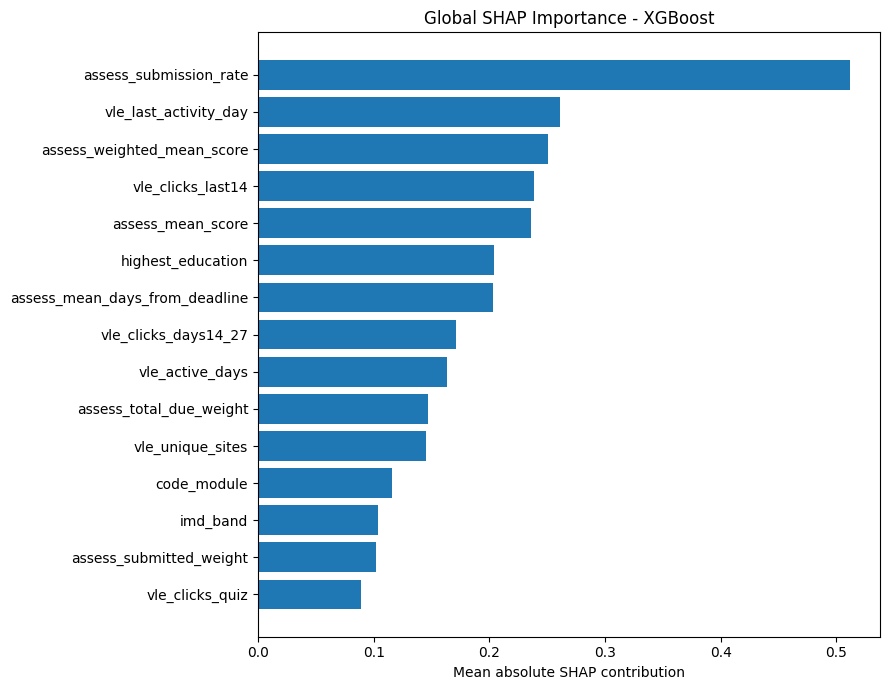

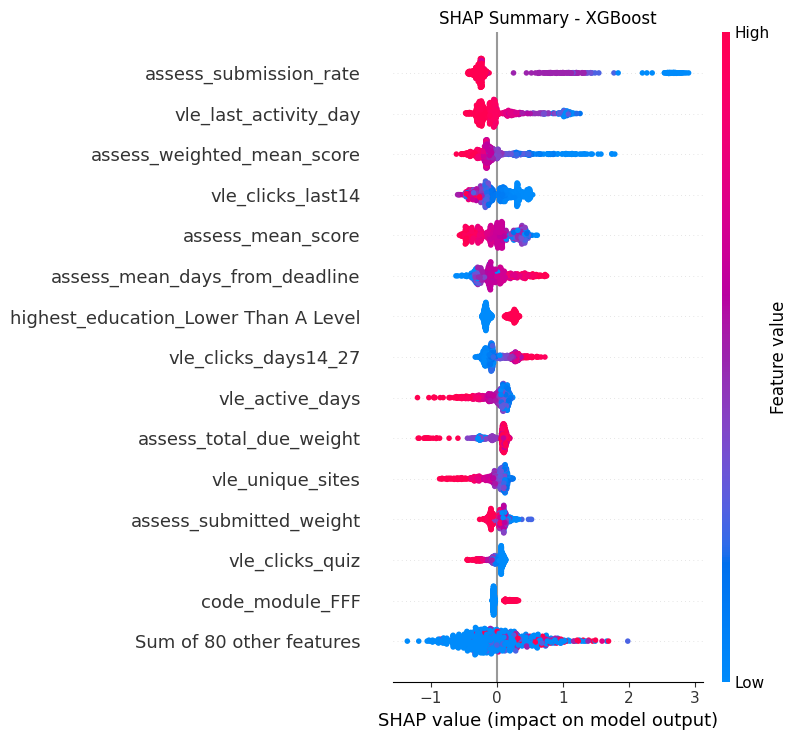

In [19]:
# I explain the final preferred model using SHAP.

preferred_preprocessor = (
    preferred_model
    .named_steps[
        "preprocess"
    ]
)


preferred_estimator = (
    preferred_model
    .named_steps[
        "model"
    ]
)


X_train_transformed = np.asarray(
    preferred_preprocessor.transform(
        X_train_full
    )
)


X_test_transformed = np.asarray(
    preferred_preprocessor.transform(
        X_test
    )
)


transformed_names = np.array(
    preferred_preprocessor
    .get_feature_names_out()
)


transformed_names = np.array([
    str(name)
    .replace(
        "numeric__",
        ""
    )
    .replace(
        "categorical__",
        ""
    )

    for name in transformed_names
])


# I map encoded features back to their original variables.

feature_map = []


for col in numeric_cols:

    feature_map.append(
        col
    )


if categorical_cols:

    fitted_encoder = (
        preferred_preprocessor
        .named_transformers_[
            "categorical"
        ]
        .named_steps[
            "onehot"
        ]
    )


    for original_col, categories in zip(
        categorical_cols,
        fitted_encoder.categories_
    ):

        for _ in categories:

            feature_map.append(
                original_col
            )


feature_map = np.array(
    feature_map
)


assert (
    len(
        feature_map
    )
    ==
    X_train_transformed.shape[
        1
    ]
)


rng = np.random.default_rng(
    RANDOM_STATE
)


background_n = min(
    250,
    len(
        X_train_transformed
    )
)


background_indices = rng.choice(
    len(
        X_train_transformed
    ),
    size=background_n,
    replace=False
)


shap_background = (
    X_train_transformed[
        background_indices
    ]
)


sample_n = min(
    800,
    len(
        X_test_transformed
    )
)


sample_indices = rng.choice(
    len(
        X_test_transformed
    ),
    size=sample_n,
    replace=False
)


X_shap = (
    X_test_transformed[
        sample_indices
    ]
)


if isinstance(
    preferred_estimator,
    LogisticRegression
):

    explainer = shap.LinearExplainer(
        preferred_estimator,
        shap_background
    )

else:

    explainer = shap.TreeExplainer(
        preferred_estimator
    )


shap_output = explainer(
    X_shap
)


shap_values = np.asarray(
    shap_output.values
)


if shap_values.ndim == 3:

    shap_values = (
        shap_values[
            :,
            :,
            1
        ]
    )


original_features = list(
    dict.fromkeys(
        feature_map
    )
)


shap_rows = []


for feature in original_features:

    mask = (
        feature_map
        ==
        feature
    )


    combined = (
        shap_values[
            :,
            mask
        ]
        .sum(
            axis=1
        )
    )


    shap_rows.append({
        "feature":
            feature,

        "mean_abs_shap":
            np.mean(
                np.abs(
                    combined
                )
            )
    })


global_shap = (
    pd.DataFrame(
        shap_rows
    )
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
)


global_shap.to_csv(
    f"{TABLE_DIR}/global_shap_importance.csv",
    index=False
)


print(
    global_shap
    .head(20)
    .round(4)
    .to_string(
        index=False
    )
)


# Readable aggregated SHAP figure

top_shap = (
    global_shap
    .head(15)
    .sort_values(
        "mean_abs_shap"
    )
)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


ax.barh(
    top_shap[
        "feature"
    ],
    top_shap[
        "mean_abs_shap"
    ]
)


ax.set_title(
    f"Global SHAP Importance - {PREFERRED_MODEL_NAME}"
)

ax.set_xlabel(
    "Mean absolute SHAP contribution"
)


plt.tight_layout()


plt.savefig(
    f"{FIG_DIR}/shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


# Technical SHAP beeswarm

base_values = np.asarray(
    shap_output.base_values
)


if base_values.ndim == 0:

    base_values = np.repeat(
        base_values,
        len(
            X_shap
        )
    )


elif base_values.ndim == 2:

    base_values = (
        base_values[
            :,
            1
        ]
    )


shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=base_values,
    data=X_shap,
    feature_names=transformed_names
)


shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    show=False
)


plt.title(
    f"SHAP Summary - {PREFERRED_MODEL_NAME}"
)


plt.tight_layout()


plt.savefig(
    f"{FIG_DIR}/shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()

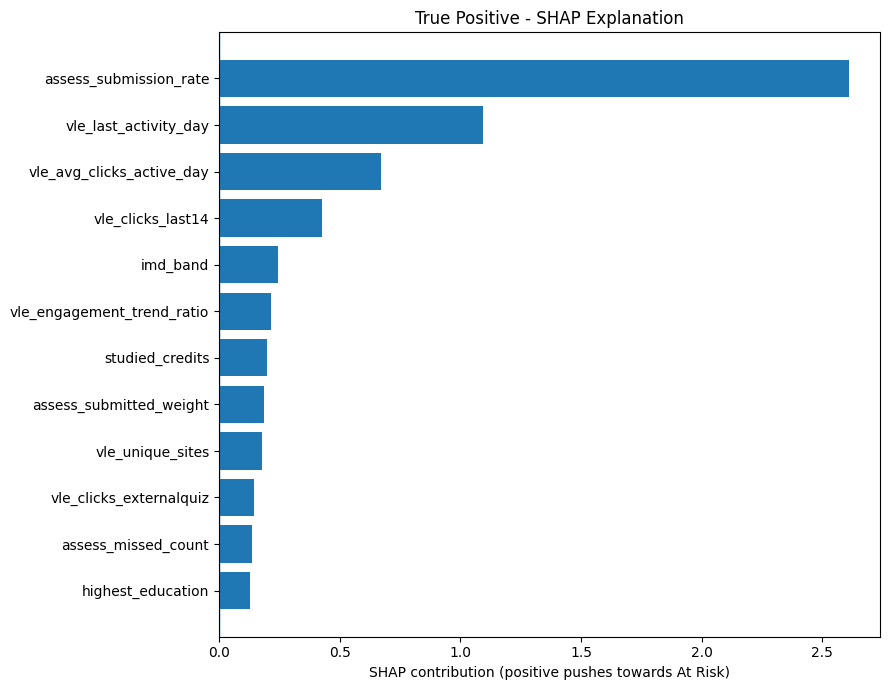

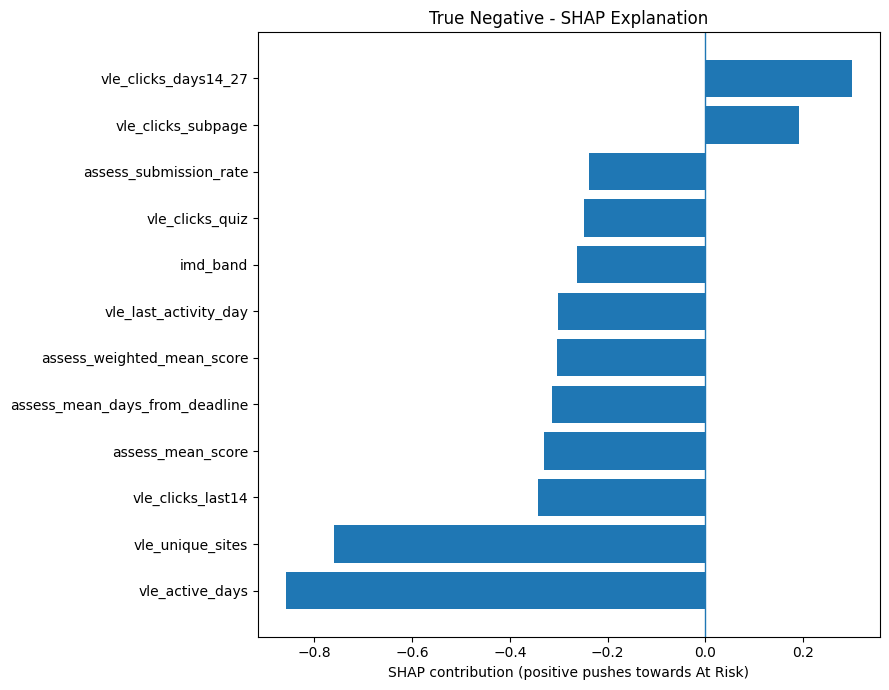

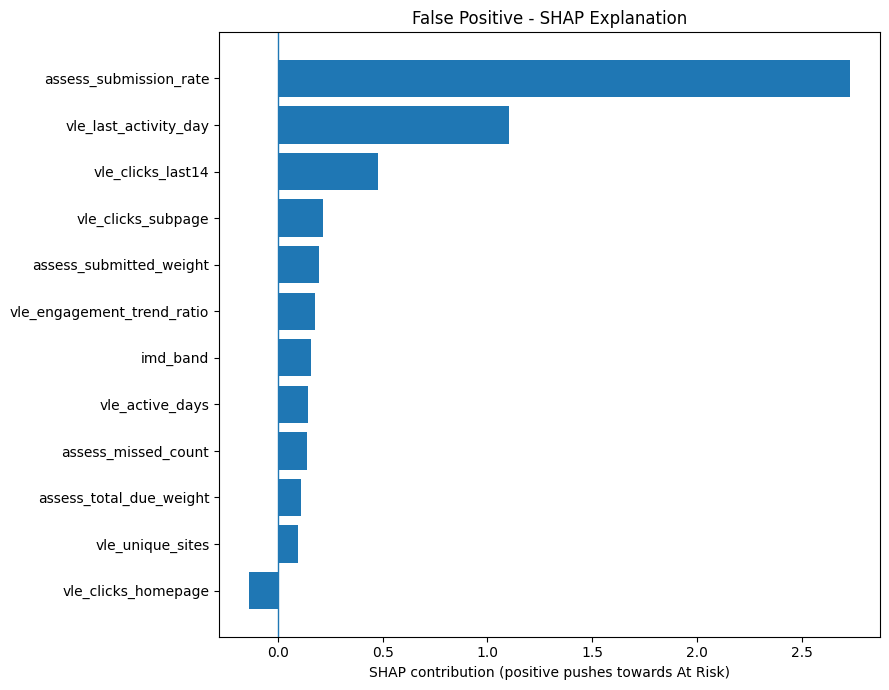

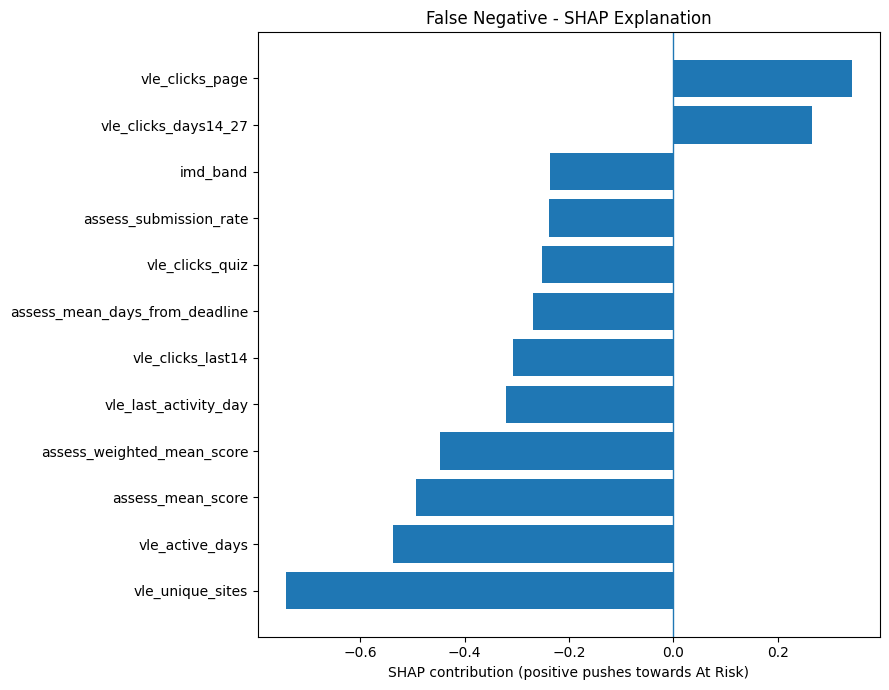

          case  id_student  actual  prediction  risk_probability
 True Positive      581909       1           1            0.9978
 True Negative      895524       0           0            0.0111
False Positive      477412       0           1            0.9938
False Negative      335644       1           0            0.0219


In [20]:
# I examine examples of correct and incorrect predictions.

def create_local_shap(
    row_position,
    case_name
):

    transformed = (
        X_test_transformed[
            row_position:
            row_position + 1
        ]
    )


    local_output = explainer(
        transformed
    )


    local_values = np.asarray(
        local_output.values
    )


    if local_values.ndim == 3:

        local_values = (
            local_values[
                :,
                :,
                1
            ]
        )


    local_values = (
        local_values[
            0
        ]
    )


    raw_row = X_test.iloc[
        row_position
    ]


    rows = []


    for feature in original_features:

        mask = (
            feature_map
            ==
            feature
        )


        contribution = (
            local_values[
                mask
            ].sum()
        )


        rows.append({
            "feature":
                feature,

            "raw_value":
                raw_row.get(
                    feature,
                    np.nan
                ),

            "shap_contribution":
                contribution,

            "absolute_contribution":
                abs(
                    contribution
                )
        })


    local_df = (
        pd.DataFrame(
            rows
        )
        .sort_values(
            "absolute_contribution",
            ascending=False
        )
    )


    safe_name = (
        case_name
        .lower()
        .replace(
            " ",
            "_"
        )
    )


    local_df.to_csv(
        f"{TABLE_DIR}/shap_{safe_name}.csv",
        index=False
    )


    top_local = (
        local_df
        .head(12)
        .sort_values(
            "shap_contribution"
        )
    )


    fig, ax = plt.subplots(
        figsize=(9, 7)
    )


    ax.barh(
        top_local[
            "feature"
        ],
        top_local[
            "shap_contribution"
        ]
    )


    ax.axvline(
        0,
        linewidth=1
    )


    ax.set_title(
        f"{case_name} - SHAP Explanation"
    )


    ax.set_xlabel(
        "SHAP contribution "
        "(positive pushes towards At Risk)"
    )


    plt.tight_layout()


    plt.savefig(
        f"{FIG_DIR}/shap_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()
    plt.close()


    return local_df


case_rows = []


for case_name in [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]:

    positions = np.where(
        error_analysis[
            "prediction_type"
        ].values
        ==
        case_name
    )[0]


    if len(
        positions
    ) == 0:

        continue


    case_probabilities = (
        preferred_probability[
            positions
        ]
    )


    if case_name in [
        "True Positive",
        "False Positive"
    ]:

        chosen = positions[
            np.argmax(
                case_probabilities
            )
        ]

    else:

        chosen = positions[
            np.argmin(
                case_probabilities
            )
        ]


    create_local_shap(
        chosen,
        case_name
    )


    case_rows.append({
        "case":
            case_name,

        "id_student":
            int(
                groups_test.iloc[
                    chosen
                ]
            ),

        "actual":
            int(
                y_test.iloc[
                    chosen
                ]
            ),

        "prediction":
            int(
                operational_prediction[
                    chosen
                ]
            ),

        "risk_probability":
            float(
                preferred_probability[
                    chosen
                ]
            )
    })


case_selection = pd.DataFrame(
    case_rows
)


case_selection.to_csv(
    f"{TABLE_DIR}/shap_case_selection.csv",
    index=False
)


print(
    case_selection
    .round(4)
    .to_string(
        index=False
    )
)

In [21]:
# I save the final model and the functions used by the prototype.

numeric_defaults = {}

numeric_ranges = {}


for col in numeric_cols:

    values = pd.to_numeric(
        X_train_full[
            col
        ],
        errors="coerce"
    )


    median_value = (
        values.median()
    )


    if pd.isna(
        median_value
    ):

        median_value = 0.0


    numeric_defaults[
        col
    ] = float(
        median_value
    )


    clean_values = (
        values.dropna()
    )


    if len(
        clean_values
    ) > 0:

        numeric_ranges[
            col
        ] = {
            "min":
                float(
                    clean_values.min()
                ),

            "max":
                float(
                    clean_values.max()
                )
        }

    else:

        numeric_ranges[
            col
        ] = {
            "min":
                0.0,

            "max":
                0.0
        }


categorical_defaults = {}

categorical_options = {}


for col in categorical_cols:

    values = (
        X_train_full[
            col
        ]
        .dropna()
        .astype(str)
    )


    if len(
        values
    ) > 0:

        categorical_defaults[
            col
        ] = (
            values
            .mode()
            .iloc[0]
        )


        categorical_options[
            col
        ] = sorted(
            values
            .unique()
            .tolist()
        )

    else:

        categorical_defaults[
            col
        ] = ""


        categorical_options[
            col
        ] = [
            ""
        ]


bundle = {
    "pipeline":
        preferred_model,

    "preferred_model_name":
        PREFERRED_MODEL_NAME,

    "prediction_day":
        PREDICTION_DAY,

    "operating_threshold":
        OPERATING_THRESHOLD,

    "feature_columns":
        feature_columns,

    "numeric_columns":
        numeric_cols,

    "categorical_columns":
        categorical_cols,

    "numeric_defaults":
        numeric_defaults,

    "numeric_ranges":
        numeric_ranges,

    "categorical_defaults":
        categorical_defaults,

    "categorical_options":
        categorical_options,

    "feature_map":
        feature_map.tolist(),

    "shap_background":
        shap_background,

    "cv_results":
        cv_results.to_dict(
            orient="records"
        ),

    "test_results":
        test_results.to_dict(
            orient="records"
        ),

    "operational_result":
        operational_result.to_dict(
            orient="records"
        ),

    "global_shap":
        global_shap.to_dict(
            orient="records"
        ),

    "subgroup_results":
        subgroup_results.to_dict(
            orient="records"
        )
}


MODEL_PATH = (
    f"{MODEL_DIR}/"
    "best_model_bundle.joblib"
)


joblib.dump(
    bundle,
    MODEL_PATH,
    compress=3
)


SAMPLE_PATH = (
    f"{MODEL_DIR}/sample_input.csv"
)


X_test.iloc[
    [0]
].to_csv(
    SAMPLE_PATH,
    index=False
)


app_utils_code = r'''
import numpy as np


def validate_feature_frame(
    frame,
    required_features
):

    if len(frame) != 1:

        return (
            False,
            "The CSV must contain exactly one row."
        )


    missing = [
        col
        for col in required_features
        if col not in frame.columns
    ]


    if missing:

        return (
            False,
            "Missing features: "
            + ", ".join(missing)
        )


    return (
        True,
        "Valid feature row."
    )


def update_manual_features(row):

    errors = []


    due = float(
        row.get(
            "assess_due_count",
            0
        )
        or 0
    )


    submitted = float(
        row.get(
            "assess_submitted_count",
            0
        )
        or 0
    )


    if submitted > due:

        errors.append(
            "Submitted assessments cannot exceed assessments due."
        )


    if "assess_missed_count" in row:

        row[
            "assess_missed_count"
        ] = max(
            due - submitted,
            0
        )


    if "assess_submission_rate" in row:

        row[
            "assess_submission_rate"
        ] = (
            submitted / due
            if due > 0
            else np.nan
        )


    total = float(
        row.get(
            "vle_total_clicks",
            0
        )
        or 0
    )


    active_days = float(
        row.get(
            "vle_active_days",
            0
        )
        or 0
    )


    first14 = float(
        row.get(
            "vle_clicks_first14",
            0
        )
        or 0
    )


    middle14 = float(
        row.get(
            "vle_clicks_days14_27",
            0
        )
        or 0
    )


    last14 = float(
        row.get(
            "vle_clicks_last14",
            0
        )
        or 0
    )


    if (
        first14
        +
        middle14
        +
        last14
        >
        total
    ):

        errors.append(
            "Selected VLE time-window clicks cannot exceed total clicks."
        )


    if (
        total > 0
        and
        active_days <= 0
    ):

        errors.append(
            "Active days must be above zero when clicks exist."
        )


    if "vle_avg_clicks_active_day" in row:

        row[
            "vle_avg_clicks_active_day"
        ] = (
            total / active_days
            if active_days > 0
            else 0
        )


    if "vle_engagement_trend_ratio" in row:

        row[
            "vle_engagement_trend_ratio"
        ] = (
            last14 + 1
        ) / (
            first14 + 1
        )


    return (
        row,
        errors
    )
'''


APP_UTILS_PATH = (
    f"{MODEL_DIR}/app_utils.py"
)


with open(
    APP_UTILS_PATH,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        app_utils_code
    )


print(
    "Model saved:",
    MODEL_PATH
)


print(
    "Sample input saved:",
    SAMPLE_PATH
)

Model saved: /content/project_outputs_FINAL/models/best_model_bundle.joblib
Sample input saved: /content/project_outputs_FINAL/models/sample_input.csv


In [22]:
# I create the final decision-support application.

app_code = r'''
from pathlib import Path

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import shap

from app_utils import (
    validate_feature_frame,
    update_manual_features
)


BASE_DIR = Path(__file__).resolve().parent


bundle = joblib.load(
    BASE_DIR / "best_model_bundle.joblib"
)


model = bundle["pipeline"]

features = bundle["feature_columns"]

numeric = bundle["numeric_columns"]

categorical = bundle["categorical_columns"]

numeric_defaults = bundle["numeric_defaults"]

numeric_ranges = bundle["numeric_ranges"]

categorical_defaults = bundle["categorical_defaults"]

categorical_options = bundle["categorical_options"]

feature_map = np.array(
    bundle["feature_map"]
)

threshold = float(
    bundle["operating_threshold"]
)


st.set_page_config(
    page_title="Academic Risk Decision Support",
    layout="wide"
)


st.title(
    "Explainable Academic Risk Decision-Support Prototype"
)


st.info(
    f"Model: {bundle['preferred_model_name']} | "
    f"Prediction point: Day {bundle['prediction_day']} | "
    f"Operating threshold: {threshold:.3f}"
)


st.warning(
    "This prototype supports professional judgement. "
    "It must not be used as an automated academic decision system."
)


tabs = st.tabs([
    "Prediction",
    "Performance",
    "Global Explainability",
    "Subgroups",
    "Responsible Use"
])


with tabs[0]:

    st.subheader(
        "Student Risk Prediction"
    )


    input_mode = st.radio(
        "Input method",
        [
            "Upload complete feature CSV",
            "Manual demonstration"
        ]
    )


    prediction_df = None


    if input_mode == "Upload complete feature CSV":

        uploaded = st.file_uploader(
            "Upload one complete student feature row",
            type=["csv"]
        )


        if uploaded is not None:

            uploaded_df = pd.read_csv(
                uploaded
            )


            valid, message = validate_feature_frame(
                uploaded_df,
                features
            )


            if not valid:

                st.error(
                    message
                )

            else:

                prediction_df = (
                    uploaded_df[
                        features
                    ]
                    .copy()
                )


    else:

        st.caption(
            "Manual mode is for demonstration. "
            "Features not shown remain at training-set defaults."
        )


        row = {}


        for col in features:

            if col in numeric:

                row[col] = numeric_defaults.get(
                    col,
                    0.0
                )

            else:

                row[col] = categorical_defaults.get(
                    col,
                    ""
                )


        manual_fields = [
            "code_module",
            "code_presentation",
            "gender",
            "highest_education",
            "age_band",
            "imd_band",
            "num_of_prev_attempts",
            "studied_credits",
            "disability",
            "assess_due_count",
            "assess_submitted_count",
            "assess_mean_score",
            "assess_weighted_mean_score",
            "vle_total_clicks",
            "vle_active_days",
            "vle_clicks_first14",
            "vle_clicks_days14_27",
            "vle_clicks_last14"
        ]


        manual_fields = [
            field
            for field in manual_fields
            if field in features
        ]


        left, right = st.columns(
            2
        )


        for i, field in enumerate(
            manual_fields
        ):

            area = (
                left
                if i % 2 == 0
                else right
            )


            with area:

                if field in categorical:

                    options = categorical_options[
                        field
                    ]


                    default = categorical_defaults[
                        field
                    ]


                    index = (
                        options.index(
                            default
                        )
                        if default in options
                        else 0
                    )


                    row[
                        field
                    ] = st.selectbox(
                        field,
                        options,
                        index=index
                    )


                else:

                    limits = numeric_ranges.get(
                        field,
                        {
                            "min":
                                numeric_defaults.get(
                                    field,
                                    0.0
                                ),

                            "max":
                                numeric_defaults.get(
                                    field,
                                    0.0
                                )
                        }
                    )


                    minimum = float(
                        limits[
                            "min"
                        ]
                    )


                    maximum = float(
                        limits[
                            "max"
                        ]
                    )


                    default = float(
                        numeric_defaults.get(
                            field,
                            0.0
                        )
                    )


                    if maximum > minimum:

                        default = min(
                            max(
                                default,
                                minimum
                            ),
                            maximum
                        )


                        row[
                            field
                        ] = st.number_input(
                            field,
                            min_value=minimum,
                            max_value=maximum,
                            value=default
                        )


                    else:

                        row[
                            field
                        ] = st.number_input(
                            field,
                            value=default
                        )


        row, manual_errors = update_manual_features(
            row
        )


        if manual_errors:

            for message in manual_errors:

                st.error(
                    message
                )

        else:

            prediction_df = pd.DataFrame(
                [row]
            )[
                features
            ]


    if (
        prediction_df is not None
        and
        st.button(
            "Predict Risk",
            type="primary"
        )
    ):

        probability = (
            model
            .predict_proba(
                prediction_df
            )[0, 1]
        )


        prediction = int(
            probability
            >=
            threshold
        )


        if prediction == 1:

            st.error(
                f"AT RISK — model-estimated risk probability: "
                f"{probability:.1%}"
            )

        else:

            st.success(
                f"NOT AT RISK — model-estimated risk probability: "
                f"{probability:.1%}"
            )


        st.caption(
            "This probability is a model estimate and should "
            "not be treated as a guaranteed real-world probability."
        )


        st.progress(
            float(
                min(
                    max(
                        probability,
                        0
                    ),
                    1
                )
            )
        )


        try:

            prep = model.named_steps[
                "preprocess"
            ]


            estimator = model.named_steps[
                "model"
            ]


            transformed = np.asarray(
                prep.transform(
                    prediction_df
                )
            )


            background = np.asarray(
                bundle[
                    "shap_background"
                ]
            )


            if estimator.__class__.__name__ == "LogisticRegression":

                explainer = shap.LinearExplainer(
                    estimator,
                    background
                )

            else:

                explainer = shap.TreeExplainer(
                    estimator
                )


            output = explainer(
                transformed
            )


            values = np.asarray(
                output.values
            )


            if values.ndim == 3:

                values = values[
                    :,
                    :,
                    1
                ]


            values = values[
                0
            ]


            rows = []


            for feature in list(
                dict.fromkeys(
                    feature_map
                )
            ):

                mask = (
                    feature_map
                    ==
                    feature
                )


                rows.append({
                    "Feature":
                        feature,

                    "Input value":
                        prediction_df.iloc[
                            0
                        ].get(
                            feature,
                            np.nan
                        ),

                    "SHAP contribution":
                        values[
                            mask
                        ].sum()
                })


            explanation_table = pd.DataFrame(
                rows
            )


            explanation_table[
                "Absolute"
            ] = np.abs(
                explanation_table[
                    "SHAP contribution"
                ]
            )


            explanation_table = (
                explanation_table
                .sort_values(
                    "Absolute",
                    ascending=False
                )
                .head(12)
            )


            st.subheader(
                "Individual Explanation"
            )


            st.dataframe(
                explanation_table[
                    [
                        "Feature",
                        "Input value",
                        "SHAP contribution"
                    ]
                ],
                use_container_width=True
            )


            st.bar_chart(
                explanation_table
                .set_index(
                    "Feature"
                )[
                    "SHAP contribution"
                ]
            )


            st.caption(
                "Positive SHAP values push the model towards "
                "At Risk. Negative values push it towards "
                "Not At Risk. SHAP does not establish causality."
            )


        except Exception as error:

            st.warning(
                f"SHAP explanation unavailable: {error}"
            )


with tabs[1]:

    st.subheader(
        "Model Performance"
    )


    st.write(
        "Model-selection cross-validation"
    )


    st.dataframe(
        pd.DataFrame(
            bundle[
                "cv_results"
            ]
        ).round(4),
        use_container_width=True
    )


    st.write(
        "Final hold-out results at threshold 0.50"
    )


    st.dataframe(
        pd.DataFrame(
            bundle[
                "test_results"
            ]
        ).round(4),
        use_container_width=True
    )


    st.write(
        "Preferred model at selected operating threshold"
    )


    st.dataframe(
        pd.DataFrame(
            bundle[
                "operational_result"
            ]
        ).round(4),
        use_container_width=True
    )


with tabs[2]:

    st.subheader(
        "Global Explainability"
    )


    shap_df = pd.DataFrame(
        bundle[
            "global_shap"
        ]
    )


    st.bar_chart(
        shap_df
        .head(15)
        .set_index(
            "feature"
        )[
            "mean_abs_shap"
        ]
    )


    st.dataframe(
        shap_df.head(20),
        use_container_width=True
    )


with tabs[3]:

    st.subheader(
        "Subgroup Performance"
    )


    subgroup_df = pd.DataFrame(
        bundle[
            "subgroup_results"
        ]
    )


    st.dataframe(
        subgroup_df.round(4),
        use_container_width=True
    )


    st.warning(
        "Differences in subgroup metrics do not by themselves "
        "prove fairness or discrimination."
    )


with tabs[4]:

    st.subheader(
        "Responsible Use"
    )


    st.markdown(
        """
        - Predictions are probabilistic and may be incorrect.
        - The operating threshold was selected without using the final test set.
        - False negatives may miss students who could benefit from support.
        - False positives may create unnecessary intervention.
        - Students already withdrawn by Day 56 are excluded.
        - Withdrawal date is not a predictive feature.
        - VLE activity is an observed behaviour, not a direct measure of motivation.
        - SHAP explains the fitted model and does not establish causality.
        - OULAD represents a distance-learning context.
        - Academic staff should consider wider contextual information.
        - No adverse academic decision should be made solely from this model.
        """
    )
'''


APP_PATH = (
    f"{MODEL_DIR}/app.py"
)


with open(
    APP_PATH,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        app_code
    )


print(
    "Streamlit app saved:",
    APP_PATH
)

Streamlit app saved: /content/project_outputs_FINAL/models/app.py


In [23]:
# I run final technical checks before packaging the project.

tests = []


def add_test(
    name,
    condition,
    evidence
):

    tests.append({
        "test":
            name,

        "result":
            (
                "PASS"
                if condition
                else "FAIL"
            ),

        "evidence":
            str(
                evidence
            )
    })


add_test(
    "No final train/test student overlap",
    len(
        train_test_overlap
    ) == 0,
    len(
        train_test_overlap
    )
)


add_test(
    "No development/threshold student overlap",
    len(
        dev_threshold_overlap
    ) == 0,
    len(
        dev_threshold_overlap
    )
)


add_test(
    "final_result excluded from predictors",
    "final_result"
    not in feature_columns,
    "Not used as predictor"
)


add_test(
    "date_unregistration excluded from predictors",
    "date_unregistration"
    not in feature_columns,
    "Eligibility only"
)


eligibility_check = (
    student_registration
    .merge(
        model_df[
            KEYS
        ],
        on=KEYS,
        how="inner"
    )
)


invalid_records = eligibility_check[
    eligibility_check[
        "date_unregistration"
    ].notna()
    &
    (
        eligibility_check[
            "date_unregistration"
        ]
        <=
        PREDICTION_DAY
    )
]


add_test(
    "No students withdrawn by Day 56 remain",
    len(
        invalid_records
    ) == 0,
    len(
        invalid_records
    )
)


sample_df = (
    X_test.iloc[
        [0]
    ].copy()
)


original_probability = (
    preferred_model
    .predict_proba(
        sample_df
    )[0, 1]
)


loaded_bundle = joblib.load(
    MODEL_PATH
)


reloaded_probability = (
    loaded_bundle[
        "pipeline"
    ]
    .predict_proba(
        sample_df
    )[0, 1]
)


add_test(
    "Reloaded model gives identical probability",
    np.isclose(
        original_probability,
        reloaded_probability
    ),
    (
        f"{original_probability:.8f} vs "
        f"{reloaded_probability:.8f}"
    )
)


# I test missing numeric input.

missing_test = (
    sample_df.copy()
)


if len(
    numeric_cols
) > 0:

    missing_test.loc[
        missing_test.index[
            0
        ],
        numeric_cols[
            0
        ]
    ] = np.nan


try:

    missing_probability = (
        preferred_model
        .predict_proba(
            missing_test
        )[0, 1]
    )


    missing_pass = (
        0
        <=
        missing_probability
        <=
        1
    )

except Exception as error:

    missing_pass = False

    missing_probability = error


add_test(
    "Model handles missing numeric input",
    missing_pass,
    missing_probability
)


# I test an unseen category.

unseen_test = (
    sample_df.copy()
)


if len(
    categorical_cols
) > 0:

    unseen_test.loc[
        unseen_test.index[
            0
        ],
        categorical_cols[
            0
        ]
    ] = "__UNSEEN_CATEGORY__"


try:

    unseen_probability = (
        preferred_model
        .predict_proba(
            unseen_test
        )[0, 1]
    )


    unseen_pass = (
        0
        <=
        unseen_probability
        <=
        1
    )

except Exception as error:

    unseen_pass = False

    unseen_probability = error


add_test(
    "Model handles unseen category",
    unseen_pass,
    unseen_probability
)


add_test(
    "Operating threshold is valid",
    (
        0
        <
        OPERATING_THRESHOLD
        <
        1
    ),
    OPERATING_THRESHOLD
)


add_test(
    "Brier score is valid",
    (
        0
        <=
        operational_result.loc[
            0,
            "brier_score"
        ]
        <=
        1
    ),
    operational_result.loc[
        0,
        "brier_score"
    ]
)


add_test(
    "SHAP mapping matches transformed features",
    len(
        feature_map
    )
    ==
    X_test_transformed.shape[
        1
    ],
    (
        f"{len(feature_map)} mapped, "
        f"{X_test_transformed.shape[1]} transformed"
    )
)


# I check both Python files compile.

for path in [
    APP_PATH,
    APP_UTILS_PATH
]:

    try:

        py_compile.compile(
            path,
            doraise=True
        )


        compile_pass = True

        compile_message = (
            "Valid Python syntax"
        )

    except Exception as error:

        compile_pass = False

        compile_message = error


    add_test(
        f"{os.path.basename(path)} compiles",
        compile_pass,
        compile_message
    )


# I load the same validation functions used by Streamlit.

spec = importlib.util.spec_from_file_location(
    "app_utils",
    APP_UTILS_PATH
)


app_utils = importlib.util.module_from_spec(
    spec
)


spec.loader.exec_module(
    app_utils
)


valid_frame = (
    X_test.iloc[
        [0]
    ].copy()
)


valid_ok, valid_message = (
    app_utils.validate_feature_frame(
        valid_frame,
        feature_columns
    )
)


add_test(
    "One-row complete CSV is accepted",
    valid_ok,
    valid_message
)


two_row_frame = (
    X_test.iloc[
        [0, 1]
    ].copy()
)


two_ok, two_message = (
    app_utils.validate_feature_frame(
        two_row_frame,
        feature_columns
    )
)


add_test(
    "Multi-row CSV is rejected",
    not two_ok,
    two_message
)


missing_column_frame = (
    X_test.iloc[
        [0]
    ]
    .drop(
        columns=[
            feature_columns[
                0
            ]
        ]
    )
)


missing_ok, missing_message = (
    app_utils.validate_feature_frame(
        missing_column_frame,
        feature_columns
    )
)


add_test(
    "Incomplete CSV is rejected",
    not missing_ok,
    missing_message
)


artefact_tests = pd.DataFrame(
    tests
)


artefact_tests.to_csv(
    f"{TEST_DIR}/artefact_test_results.csv",
    index=False
)


print(
    artefact_tests
    .to_string(
        index=False
    )
)


# I create a manual Streamlit test plan for final screenshots.

manual_test_plan = pd.DataFrame([
    {
        "test_id":
            "M1",

        "test":
            "Upload sample_input.csv",

        "expected_result":
            "Prediction and SHAP explanation displayed",

        "status":
            "TO TEST"
    },
    {
        "test_id":
            "M2",

        "test":
            "Upload CSV containing two rows",

        "expected_result":
            "Application rejects file",

        "status":
            "TO TEST"
    },
    {
        "test_id":
            "M3",

        "test":
            "Upload CSV with one required feature removed",

        "expected_result":
            "Application reports missing feature",

        "status":
            "TO TEST"
    },
    {
        "test_id":
            "M4",

        "test":
            "Manual submissions exceed assessments due",

        "expected_result":
            "Application rejects inconsistent input",

        "status":
            "TO TEST"
    },
    {
        "test_id":
            "M5",

        "test":
            "Manual VLE windows exceed total clicks",

        "expected_result":
            "Application rejects inconsistent input",

        "status":
            "TO TEST"
    },
    {
        "test_id":
            "M6",

        "test":
            "Valid manual input",

        "expected_result":
            "Prediction and explanation displayed",

        "status":
            "TO TEST"
    }
])


manual_test_plan.to_csv(
    f"{TEST_DIR}/manual_streamlit_test_plan.csv",
    index=False
)


run_configuration = {
    "run_type":
        "FINAL",

    "prediction_day":
        PREDICTION_DAY,

    "random_state":
        RANDOM_STATE,

    "cv_folds":
        CV_FOLDS,

    "model_selection_metric":
        "PR-AUC, then F1, then Recall",

    "original_records":
        int(
            original_n
        ),

    "excluded_on_or_before_day56":
        int(
            excluded_n
        ),

    "eligible_records":
        int(
            len(
                model_df
            )
        ),

    "model_development_records":
        int(
            len(
                X_dev
            )
        ),

    "threshold_validation_records":
        int(
            len(
                X_threshold
            )
        ),

    "final_training_records":
        int(
            len(
                X_train_full
            )
        ),

    "holdout_test_records":
        int(
            len(
                X_test
            )
        ),

    "input_features":
        int(
            len(
                feature_columns
            )
        ),

    "transformed_features":
        int(
            X_train_transformed.shape[
                1
            ]
        ),

    "preferred_model":
        PREFERRED_MODEL_NAME,

    "threshold_selection":
        "Separate grouped validation set using F2",

    "operating_threshold":
        float(
            OPERATING_THRESHOLD
        ),

    "class_weight_used":
        bool(
            USE_CLASS_WEIGHT
        )
}


with open(
    f"{OUTPUT_DIR}/run_configuration.json",
    "w"
) as file:

    json.dump(
        run_configuration,
        file,
        indent=2
    )


import sklearn
import xgboost


requirements = f"""streamlit
pandas=={pd.__version__}
numpy=={np.__version__}
scikit-learn=={sklearn.__version__}
xgboost=={xgboost.__version__}
shap=={shap.__version__}
joblib
"""


with open(
    f"{MODEL_DIR}/requirements.txt",
    "w"
) as file:

    file.write(
        requirements
    )


readme = f"""
EXPLAINABLE ACADEMIC RISK PROTOTYPE

Preferred model:
{PREFERRED_MODEL_NAME}

Prediction point:
Day {PREDICTION_DAY}

Operating threshold:
{OPERATING_THRESHOLD:.3f}

Model selection:
Five-fold grouped cross-validation on the
model-development data.

Primary model-selection metric:
PR-AUC, followed by F1 and Recall.

Threshold selection:
Separate grouped threshold-validation set
using F2.

Final evaluation:
Independent grouped hold-out test set.

Students withdrawn on or before
Day {PREDICTION_DAY} are excluded.

date_unregistration is not a predictive feature.

Run locally:

pip install -r requirements.txt

streamlit run app.py

Use sample_input.csv to test complete CSV upload.

Manual mode is a demonstration interface because
features not shown remain at training defaults.

The displayed probability is a model estimate,
not a guaranteed real-world probability.

This prototype is intended for decision support only.
"""


with open(
    f"{MODEL_DIR}/README.txt",
    "w"
) as file:

    file.write(
        readme
    )

                                        test result                              evidence
         No final train/test student overlap   PASS                                     0
    No development/threshold student overlap   PASS                                     0
       final_result excluded from predictors   PASS                 Not used as predictor
date_unregistration excluded from predictors   PASS                      Eligibility only
      No students withdrawn by Day 56 remain   PASS                                     0
  Reloaded model gives identical probability   PASS              0.04643539 vs 0.04643539
         Model handles missing numeric input   PASS                           0.046435393
               Model handles unseen category   PASS                           0.046435393
                Operating threshold is valid   PASS                                  0.19
                        Brier score is valid   PASS                   0.16373355518592939
   SHAP ma

In [24]:
# I review the final results and save all outputs in one ZIP.

print(
    "=" * 78
)

print(
    "FINAL PROJECT SUMMARY"
)

print(
    "=" * 78
)


print(
    f"""
Prediction point:
Day {PREDICTION_DAY}

Original records:
{original_n:,}

Excluded on/before Day 56:
{excluded_n:,}

Eligible modelling records:
{len(model_df):,}

Model-development records:
{len(X_dev):,}

Threshold-validation records:
{len(X_threshold):,}

Final training records:
{len(X_train_full):,}

Independent hold-out records:
{len(X_test):,}

Model-selection CV:
{CV_FOLDS}-fold StratifiedGroupKFold

Model-selection priority:
PR-AUC -> F1 -> Recall

Input features:
{len(feature_columns)}

Transformed features:
{X_train_transformed.shape[1]}

Preferred model:
{PREFERRED_MODEL_NAME}

Operating threshold:
{OPERATING_THRESHOLD:.3f}

Class weighting:
{USE_CLASS_WEIGHT}
"""
)


print(
    "\nModel-selection CV results:\n"
)


print(
    cv_results[
        [
            "model",
            "cv_accuracy",
            "cv_precision",
            "cv_recall",
            "cv_f1",
            "cv_roc_auc",
            "cv_pr_auc",
            "cv_f1_sd"
        ]
    ]
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nFinal hold-out results at threshold 0.50:\n"
)


print(
    test_results
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nPreferred model at operating threshold:\n"
)


print(
    operational_result
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nTop 15 SHAP features:\n"
)


print(
    global_shap
    .head(15)
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nSubgroup gaps:\n"
)


print(
    subgroup_gap_summary
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\nAutomated artefact tests:\n"
)


print(
    artefact_tests
    .to_string(
        index=False
    )
)


failed_tests = artefact_tests[
    artefact_tests[
        "result"
    ] != "PASS"
]


if len(
    failed_tests
) == 0:

    print(
        "\nAll automated tests passed."
    )

else:

    print(
        "\nWARNING: Some automated tests failed."
    )

    print(
        failed_tests.to_string(
            index=False
        )
    )


ZIP_PATH = (
    "/content/"
    "Sriya_Gonela_OULAD_FINAL_Project_Outputs.zip"
)


if os.path.exists(
    ZIP_PATH
):

    os.remove(
        ZIP_PATH
    )


with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:


    for root, folders, filenames in os.walk(
        OUTPUT_DIR
    ):


        for filename in filenames:

            full_path = os.path.join(
                root,
                filename
            )


            relative_path = os.path.relpath(
                full_path,
                OUTPUT_DIR
            )


            zip_file.write(
                full_path,
                arcname=relative_path
            )


print(
    "\nZIP created:"
)

print(
    ZIP_PATH
)


print(
    "\nZIP size:",
    round(
        os.path.getsize(
            ZIP_PATH
        )
        /
        (
            1024
            *
            1024
        ),
        2
    ),
    "MB"
)


print(
    "\nSaved project files:\n"
)


for root, folders, filenames in os.walk(
    OUTPUT_DIR
):

    for filename in sorted(
        filenames
    ):

        print(
            os.path.relpath(
                os.path.join(
                    root,
                    filename
                ),
                OUTPUT_DIR
            )
        )


from google.colab import files


files.download(
    ZIP_PATH
)

FINAL PROJECT SUMMARY

Prediction point:
Day 56

Original records:
32,593

Excluded on/before Day 56:
6,071

Eligible modelling records:
26,522

Model-development records:
16,992

Threshold-validation records:
4,233

Final training records:
21,225

Independent hold-out records:
5,297

Model-selection CV:
5-fold StratifiedGroupKFold

Model-selection priority:
PR-AUC -> F1 -> Recall

Input features:
56

Transformed features:
94

Preferred model:
XGBoost

Operating threshold:
0.190

Class weighting:
False


Model-selection CV results:

              model  cv_accuracy  cv_precision  cv_recall  cv_f1  cv_roc_auc  cv_pr_auc  cv_f1_sd
Logistic Regression       0.7657        0.7746     0.6224 0.6901      0.8309     0.8068    0.0046
      Random Forest       0.7671        0.7791     0.6204 0.6906      0.8295     0.8101    0.0075
            XGBoost       0.7683        0.7724     0.6343 0.6965      0.8337     0.8149    0.0051

Final hold-out results at threshold 0.50:

              model  thre

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>